# Data Analytics in Supply Chain Management
## Preprocessing — Port Logistics Dispatching

Scenario. Imagine that you are working in a port-logistics control tower. A truck, trailer, swap 
body, or container is approaching a terminal, but the operating situation is constantly changing: 
traffic builds up, a terminal incident occurs, a slot is about to be missed, a driver is running out 
of available hours, or a vehicle develops a technical warning. A dispatcher must quickly decide 
what to do next. 

# Feature Dictionary

| Feature | Type | Description |
|---|---|---|
| **Observation_ID** | Integer | Unique case number. Exclude from predictive modeling. |
| **Event_Timestamp** | Datetime | Time at which the dispatch decision is evaluated. Can be transformed into meaningful calendar features. |
| **Day_of_Week** | Categorical | Day of the week, Mon–Sun. |
| **Shift** | Categorical | Day, Evening, or Night operating shift. |
| **Terminal_ID** | Categorical | Fictional terminal code T1–T4. Terminals have different baseline congestion patterns. |
| **Corridor_ID** | Categorical | Fictional hinterland corridor C1–C5 with different traffic/reliability profiles. |
| **Transport_Object_Type** | Categorical | Trailer, Swap_Body, or Container. |
| **Vehicle_Type** | Categorical | Vehicle configuration used for the transport case. |
| **Distance_to_Terminal_km** | Numeric | Remaining distance to the terminal in kilometers. |
| **Weather_Severity_Index** | Numeric | Synthetic 0–100 weather-severity score. Severe weather is intentionally rare. |
| **Terminal_Incident_Severity** | Ordinal | Terminal incident severity from 0 (none) to 3 (severe). |
| **Road_Incident_Severity** | Ordinal | Road incident severity from 0 (none) to 3 (severe). |
| **Terminal_Congestion_Index** | Numeric | 0–100 index describing terminal congestion. |
| **Road_Congestion_Index** | Numeric | 0–100 index describing corridor traffic congestion. |
| **Yard_Occupancy_pct** | Numeric | Estimated yard utilization. A small number of values are intentionally missing. |
| **Queue_Length_vehicles** | Integer | Number of vehicles currently waiting in the terminal/gate process. |
| **Gate_Processing_Time_min** | Numeric | Expected minutes needed for gate and handling activities. |
| **Expected_Disruption_Duration_min** | Numeric | Estimated duration of the current disruption. Short and long disruptions can lead to different actions. |
| **Current_Delay_min** | Numeric | Accumulated delay in minutes at the decision time. |
| **ETA_Uncertainty_min** | Numeric | Uncertainty around the ETA estimate in minutes. Some values are intentionally missing. |
| **Slot_Window_min** | Integer | Length of the assigned terminal time window: 30, 45, 60, or 90 minutes. |
| **Slot_Buffer_min** | Numeric | Estimated remaining slack before slot failure. Negative values indicate an expected slot miss. |
| **Trailer_Ready** | Boolean | Whether the required trailer or swap body is ready for the planned operation. |
| **Customs_Status** | Categorical | Clearance state: Cleared, Pending, or Hold. |
| **Vehicle_Technical_Status** | Categorical | Vehicle state: OK, Warning, or Critical. |
| **Remaining_Driver_Hours** | Numeric | Remaining legal/operational driver time. |
| **Cargo_Priority** | Ordinal | Service priority from 1 (normal) to 3 (high). |
| **Service_Level_Penalty_EUR** | Numeric | Synthetic financial exposure if the service commitment is missed. |
| **Vehicle_Load_Factor_pct** | Numeric | Vehicle utilization in percent. |
| **Empty_Km_Ratio_pct** | Numeric | Share of empty distance associated with the case or recent operation. |
| **Alternative_Slot_Available** | Boolean | Whether an alternative terminal slot is available. |
| **Alternative_Terminal_Available** | Boolean | Whether another terminal option is operationally available. |
| **Alternative_Route_Available** | Boolean | Whether a feasible alternative road route exists. |
| **Alternative_Route_Extra_km** | Numeric | Additional distance of the best alternative route. Blank when no alternative route exists. |
| **Nearby_Compatible_Vehicles** | Integer | Number of nearby vehicles that could potentially replace the assigned vehicle. |
| **Driver_Change_Available** | Boolean | Whether a driver substitution is available. |
| **Historical_Route_Reliability_pct** | Numeric | Historical reliability of the corridor. A small number of values are intentionally missing. |
| **Disruptions_Last_7d** | Integer | Number of recent disruptions in the relevant route/terminal context. |
| **Data_Quality_Score_pct** | Numeric | Synthetic data-quality score representing completeness and validity of available operational data. |
| **Estimated_CO2_kg** | Numeric | Estimated CO2 associated with the case, based on distance, load, and delay. |
| **Recommended_Dispatch_Action** | Categorical | Six-class outcome to predict: PROCEED_AS_PLANNED, WAIT_AND_MONITOR, RESCHEDULE_SLOT, REROUTE, REASSIGN_VEHICLE, or PRIORITY_RECOVERY. |

In [35]:
# -*- coding: utf-8 -*-
"""
Created on Tue Mar 1 07:37:58 2022

@author: hwicaksono
"""

import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelBinarizer
from sklearn.preprocessing import MaxAbsScaler

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


# Load the dataset

In [36]:

df = pd.read_csv(r"../data/Classification_logistics.csv")
df

,Observation_ID,Event_Timestamp,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,...,Alternative_Terminal_Available,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action
0,1,2027-04-29 06:20:00,Thu,Day,T1,C1,Container,Tractor_Unit,92.88,8.64,...,False,True,3.99,1.0,False,88.36,5.0,96.20,90.02,PRIORITY_RECOVERY
1,2,2027-06-27 14:36:00,Sun,Evening,T1,C4,Trailer,Tractor_Unit,88.66,26.61,...,False,False,NaN,0.0,False,89.85,5.0,94.98,68.10,PROCEED_AS_PLANNED
2,3,2026-12-02 22:51:00,Wed,Night,T4,C3,Trailer,Tractor_Unit,30.60,19.01,...,False,True,35.86,4.0,True,90.22,3.0,98.44,20.00,PROCEED_AS_PLANNED
3,4,2026-12-30 17:45:00,Wed,Evening,T2,C1,Container,Tractor_Unit,97.52,8.60,...,False,True,27.85,2.0,False,89.08,6.0,98.77,61.87,REASSIGN_VEHICLE
4,5,2027-02-01 00:14:00,Mon,Night,T3,C3,Swap_Body,Rigid_Truck,129.40,13.18,...,False,True,10.68,3.0,True,89.24,4.0,97.78,104.38,REASSIGN_VEHICLE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10245,1510,2026-12-15 01:19:00,Tue,Night,T4,C5,Swap_Body,SWAP_BODY_TRUCK,21.12,40.09,...,True,False,NaN,3.0,False,91.47,2.0,99.20,NaN,WAIT_AND_MONITOR
10246,6443,2027-07-01 16:16:00,Thu,Evening,T2,C2,Trailer,Rigid_Truck,48.93,17.57,...,True,True,27.43,1.0,True,88.36,5.0,100.00,41.63,WAIT_AND_MONITOR
10247,3071,2027-07-29 13:03:00,Thu,DAY,T2,C5,Swap_Body,Swap_Body_Truck,87.72,16.33,...,False,True,24.17,2.0,False,89.46,3.0,100.00,61.03,PRIORITY_RECOVERY
10248,3016,2027-08-17 14:44:00,Tue,Day,T2,C4,Swap_Body,Swap_Body_Truck,29.70,NaN,...,True,True,28.98,1.0,False,89.47,2.0,96.20,22.24,WAIT_AND_MONITOR


# Describe Statistics of the dataset
the objective is to identify potential data quality issues that are deterministic and should be fixed
before the train/test split.
Examples include duplicates, inconsistencies in the columns (for example day of the week column has 35 unique values but normally should be 7, same for shift it has 15 unique values but normally should be 3), boolean columns stored as object (can be casted to bool)

In [37]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Observation_ID,10250.0,NaN,NaN,NaN,4997.198829,2887.196253,1.0,2502.25,4997.5,7501.75,10000.0
Event_Timestamp,10250,9906,2026-12-21 07:48:00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Day_of_Week,10146,35,Tue,1468,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shift,10148,15,Evening,3301,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Terminal_ID,10148,4,T1,3248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Corridor_ID,10146,5,C2,2263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transport_Object_Type,10148,3,Trailer,4634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle_Type,10146,21,Tractor_Unit,5956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance_to_Terminal_km,10147.0,NaN,NaN,NaN,73.051751,74.898737,5.0,35.365,54.66,86.03,842.05
Weather_Severity_Index,10144.0,NaN,NaN,NaN,17.197026,13.918204,0.02,6.9375,13.405,23.6,98.01


# Part 1: Handling data quality issues

## A. Deterministic data-quality fixes

The dataset currently contains **10,250 rows**. No cleaning has been applied yet — the issues below were identified from `df.describe(include='all')` and dtype inspection, and each will be resolved **before the train/test split**. Each fix is a deterministic, rule-based transformation with no fitted parameters: applying them pre-split cannot leak information, and ensures both train and test receive identical treatment.

| # | Issue | Evidence | Planned fix | Rationale |
|---|---|---|---|---|
| 1 | Duplicated `Observation_ID` values | `count = 10250` but `max = 10000` -> at least 250 rows share an ID | Count exact duplicate rows, then drop them; retain non-identical ID collisions and drop the column | IDs are drawn from a 1–10000 range, so duplicates are inevitable. Exact duplicates must be removed to prevent the same record appearing in both train and test |
| 2 | Duplicated `Event_Timestamp` values | `count = 10250`, `unique = 9906` → 344 rows share a timestamp; top value repeated 3× | Verify against exact duplicates after parsing (see #3) | Timestamp collisions alone do not imply duplicate *rows* — minute-level resolution permits distinct events. Collisions will be re-counted after parsing and interpreted then |
| 3 | `Event_Timestamp` stored as `object` (string), not `datetime64` | `dtype = object` in `describe` | Parse with `pd.to_datetime(..., errors='coerce')` | A raw timestamp string is unusable as a feature. Mixed string formats can also *hide* duplicates (`"2026-12-21 07:48:00"` vs `"2026-12-21T07:48:00"` are different strings, same instant), so duplicate counts must be recomputed after parsing |
| 4 | `Day_of_Week` label inconsistency | `unique = 35` vs 7 expected; top value `'Tue'` | Canonicalize via `DAY_MAP`, then verify no unmapped values remain | Mixed case and abbreviation: `'tue'`, `'Tue'`, `'TUE'`, `'tuesday'`, `'Tue.'` all denote one category |
| 5 | `Shift` label inconsistency | `unique = 15` vs 3 expected; top value `'Evening'` | Strip, lowercase, `replace` with canonical map | Same problem: `'EVENING'`, `'Evening'`, `' evening'` all denote one shift |
| 6 | `Vehicle_Type` label inconsistency | `unique = 21` vs 3 canonical types | Strip, lowercase, normalize separators, `replace` with canonical map | Abbreviations and separator variants (`space` / `-` / `_`) produce spurious categories |
| 7 | Five boolean columns stored as `object` | `unique = 2`, `top = 'True'` / `'False'`, `dtype = object` | Cast to nullable `boolean` | Values are string literals; `boolean` is the correct NaN-safe dtype and avoids a string category being one-hot encoded as if it were nominal |
| 8 | `Cargo_Priority` stored as numeric | `min = 1`, `median = 1`, `max = 3`, `std = 0.70` | Cast to **ordinal** `Categorical` with `categories=[1,2,3]` | Represents three priority tiers, not a continuous measurement |
| 9 | `Terminal_ID`, `Corridor_ID` stored as `object` | `unique = 4` and `5` | Cast to `category` | Nominal identifiers with a small fixed level set; category dtype preserves levels consistently across train/test |
| 10 | `Observation_ID` is not a unique key | 250 collisions (see #1) | **Drop** the column | Identifier with no predictive signal; retaining it would let the model overfit to row order |

**Order of operations.** `Event_Timestamp` is parsed *first* (item 3), and duplicate counts (items 1–2) are recomputed on the parsed values. This matters: if mixed timestamp formats were present, the raw-string duplicate count understates the true number of colliding instants, and any row that is identical only after parsing would otherwise survive as a false "distinct" row.

**Cross-field consistency.** Once `Event_Timestamp` is parsed and `Day_of_Week` canonicalized, the two are compared. They encode the same fact independently; if the labeled day contradicts the timestamp-derived weekday, the timestamp is treated as ground truth and the discrepancy is flagged — a verification step, not a silent fix.

**Note on `Alternative_Route_Extra_km`.** `count = 8032`, matching `freq = 8032` for `Alternative_Route_Available = True`. This equality indicates the column is missing *precisely when* no alternative route exists — structural missingness (MAR), not random. It is flagged here so that Section 3 excludes this column from generic imputation.

1. Parse timestamp, compare duplicate counts before vs after

In [38]:
raw_ts = df['Event_Timestamp'].astype('string')   # preserve raw strings for comparison

ts_dups_raw = raw_ts.duplicated().sum()
id_dups_raw = df.duplicated(subset=['Observation_ID']).sum()
exact_raw   = df.duplicated().sum()

df['Event_Timestamp'] = pd.to_datetime(df['Event_Timestamp'], errors='coerce')

ts_dups_parsed = df['Event_Timestamp'].duplicated().sum()
id_dups_parsed = df.duplicated(subset=['Observation_ID']).sum()
exact_parsed   = df.duplicated().sum()

print(f"{'':22s}{'raw string':>12s}{'parsed':>10s}")
print(f"{'Event_Timestamp dups':22s}{ts_dups_raw:>12d}{ts_dups_parsed:>10d}")
print(f"{'Observation_ID dups':22s}{id_dups_raw:>12d}{id_dups_parsed:>10d}")
print(f"{'Exact row dups':22s}{exact_raw:>12d}{exact_parsed:>10d}")
print(f"\nNaT after parse: {df['Event_Timestamp'].isna().sum()}")
print(f"Range: {df['Event_Timestamp'].min()} → {df['Event_Timestamp'].max()}")

                        raw string    parsed
Event_Timestamp dups           344       344
Observation_ID dups            250       250
Exact row dups                 196       196

NaT after parse: 0
Range: 2026-11-01 01:12:00 → 2027-11-01 00:43:00


In [39]:
before = len(df)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
after = len(df)

print(f"Rows: {before} → {after} (dropped {before - after})")
print(f"Residual ID dups       : {df.duplicated(subset=['Observation_ID']).sum()} (expected 54)")
print(f"Residual timestamp dups: {df.duplicated(subset=['Event_Timestamp']).sum()} (expected 148)")
print(f"Residual exact dups    : {df.duplicated().sum()} (expected 0)")

Rows: 10250 → 10054 (dropped 196)
Residual ID dups       : 54 (expected 54)
Residual timestamp dups: 148 (expected 148)
Residual exact dups    : 0 (expected 0)


**Duplicate Removal**. 196 direct duplicate rows (i.e. Same for all columns, including the 'Observation_ID' column) were dropped, reducing the dataset to 10,054 rows out of the original 10,250. The remaining collisions - 54 on 'Observation_ID' and 148 on 'Event_Timestamp' - were kept as they have at least one additional column different, which aligns with the reuse of IDs on different events and also the occurrence of different events during the same minute.

In addition, duplication removal is performed **before the split** as this is a deterministic (rule) and can't leak information. Removing duplicate records prior to splitting ensures that no duplicate records occur across the two datasets which, if not the case, would bias the results (tested performance) of the test set.

2. Label canonicalization

In [40]:
# 1. Define the mappings
SHIFT_MAP = {'day': 'Day', 'evening': 'Evening', 'night': 'Night'}
VEH_MAP = {'tractor_unit': 'Tractor_Unit', 'rigid_truck': 'Rigid_Truck', 'swap_body_truck': 'Swap_Body_Truck'}
DAY_MAP = {
    'mon': 'Monday', 'monday': 'Monday', 'mon.': 'Monday',
    'tue': 'Tuesday', 'tues': 'Tuesday', 'tuesday': 'Tuesday', 'tue.': 'Tuesday',
    'wed': 'Wednesday', 'weds': 'Wednesday', 'wednesday': 'Wednesday', 'wed.': 'Wednesday',
    'thu': 'Thursday', 'thur': 'Thursday', 'thurs': 'Thursday', 'thursday': 'Thursday', 'thu.': 'Thursday',
    'fri': 'Friday', 'friday': 'Friday', 'fri.': 'Friday',
    'sat': 'Saturday', 'saturday': 'Saturday', 'sat.': 'Saturday',
    'sun': 'Sunday', 'sunday': 'Sunday', 'sun.': 'Sunday'
}

# 2. Extract clean raw strings for checking
day_raw = (df['Day_of_Week'].astype('string').str.strip()
           .str.replace(r'\s+', ' ', regex=True).str.rstrip('.,').str.lower())
shift_raw = df['Shift'].astype('string').str.strip().str.lower()
veh_raw = (df['Vehicle_Type'].astype('string').str.strip().str.lower()
           .str.replace(r'[\s\-]+', '_', regex=True).str.replace(r'_+', '_', regex=True))

# 3. Check for unmapped values BEFORE applying
for name, raw, mp in [('Day_of_Week', day_raw, DAY_MAP), ('Shift', shift_raw, SHIFT_MAP), ('Vehicle_Type', veh_raw, VEH_MAP)]:
    unmapped = raw[~raw.isin(mp) & raw.notna()].unique()
    print(f"{name} unmapped: {list(unmapped) if len(unmapped) else '(none)'}")

# 4. Apply mappings and cast to category
df['Day_of_Week']  = day_raw.map(DAY_MAP).astype('category')
df['Shift']        = shift_raw.replace(SHIFT_MAP).astype('category')
df['Vehicle_Type'] = veh_raw.replace(VEH_MAP).astype('category')

Day_of_Week unmapped: (none)
Shift unmapped: (none)
Vehicle_Type unmapped: (none)


Exploratory data analysis indicated that there was severe label inconsistency for three of the categorical columns. The `Day_of_Week` column contained `35` unique values as compared to `7` expected; the `Shift` column held `15` unique values as compared to `3`; and the `Vehicle_Type` column indicated `21` unique values as opposed to `3`. This is most likely due to mixed case ('EVENING', 'Evening') and trailing whitespace and punctuation ('Tue ', 'Tue.', 'sun', 'Sun ', 'Sun.', 'sound', 'Sound') as well as separator formats ('swap-body-truck', 'swap body truck', 'Swap_Body_Truck').
The following normalised the raw strings by removing whitespace, unifying case, and standardising separators, and then mapped them to a canonical vocabulary by way of explicit dictionaries (`DAY_MAP`, `SHIFT_MAP`, `VEH_MAP`):
Before casting the columns to the `category` data type, it was verified explicitly that no raw values outside of the dictionaries were observed: such verification, which is important to avoid silently losing data if the `.map()` were to escape any unhandled variant to `NaN`. the results for all the three columns was`(none)`, which confirms that all the non-null values were successfully mapped.  this transformation was performed before the train/test split as it is rule-based and deterministic, does not adhere to any statistical distributions from the data, and therefore is unlikely to leak. This ensures the subsequent categorical encoders will recognise all levels in the training and test data.

3. Strip remaining object columns

In [41]:
for c in ['Customs_Status','Vehicle_Technical_Status','Terminal_ID',
          'Corridor_ID','Transport_Object_Type','Recommended_Dispatch_Action']:
    df[c] = df[c].astype('string').str.strip().str.replace(r'\s+',' ',regex=True)

print("Unstripped:", sum((df[c] != df[c].astype('string').str.strip()).sum()
                         for c in df.select_dtypes('object').columns))

Unstripped: 0


4. Boolean Casting

In [42]:
BOOL_COLS = ['Trailer_Ready', 'Alternative_Slot_Available', 
             'Alternative_Terminal_Available', 'Alternative_Route_Available', 
             'Driver_Change_Available']

for c in BOOL_COLS:
    df[c] = (df[c].astype('string')
                    .str.strip()
                    .str.lower()
                    .map({'true': True, 'false': False, '1': True, '0': False})
                    .astype('boolean'))

print(df[BOOL_COLS].dtypes.value_counts())
print("Missing values in boolean columns:", df[BOOL_COLS].isnull().sum().sum())

boolean    5
Name: count, dtype: int64
Missing values in boolean columns: 0


Five columns of binary operational flags were stored as the object type (e.g. `'False'` and `'True'`) from the original data, including the following flags: - `Trailer_Ready` - `Alternative_Slot_Available` - `Alternative_Terminal_Available` - `Alternative_Route_Available` - `Driver_Change_Available` Data Type Changes: Instead of being in string literal form, we change them from string literals to boolean logic types (and also cast them to pandas' optional `boolean` dtype). Why are this change necessary? Theoretically speaking, these variables could be thought of as *nominal (binary) variables* (e.g. Trailer is either ready or not). If they remain as object (string), then the categorical encoders will likely interpret them as three level categorical variables (['True', 'False', and `NaN`) which will introduce unnecessary dummy variables. Turning them into `boolean` (and later on being fed as 0/1s for modeling) allows us to use *binary label encoding*. Furthermore, leveraging pandas' nullable `boolean` type (with a capital "B") rather than a Python `bool` type prevents the failure of casting or silent coercion of missing values (`NaN`) to `False`. This is deterministically corrected before the data is split so that all subsequent models and encoders correctly interpret the flags as binary nominal features.

5. Data types correction

In [43]:
# 1. Ordinal Casting (Ordered Categories)
print("Cargo_Priority:\n", df['Cargo_Priority'].value_counts(dropna=False))
print("\nRoad_Incident_Severity:\n", df['Road_Incident_Severity'].value_counts(dropna=False))
print("Terminal_Incident_Severity:\n", df['Terminal_Incident_Severity'].value_counts(dropna=False))
df['Cargo_Priority'] = pd.Categorical(df['Cargo_Priority'], ordered=True, categories=[1, 2, 3])
df['Terminal_Incident_Severity'] = pd.Categorical(df['Terminal_Incident_Severity'], ordered=True, categories=[0, 1, 2, 3])
df['Road_Incident_Severity'] = pd.Categorical(df['Road_Incident_Severity'], ordered=True, categories=[0, 1, 2, 3])
df['Vehicle_Technical_Status'] = pd.Categorical(df['Vehicle_Technical_Status'], ordered=True, categories=['OK', 'Warning', 'Critical'])

# 2. Nominal Casting (Unordered Categories)
df['Terminal_ID'] = df['Terminal_ID'].astype('category')
df['Corridor_ID'] = df['Corridor_ID'].astype('category')

print(df[['Cargo_Priority', 'Terminal_Incident_Severity', 'Road_Incident_Severity','Vehicle_Technical_Status','Terminal_ID', 'Corridor_ID']].dtypes)

Cargo_Priority:
 Cargo_Priority
1.0    6072
2.0    2656
3.0    1224
NaN     102
Name: count, dtype: int64

Road_Incident_Severity:
 Road_Incident_Severity
0.0    8715
1.0     827
2.0     307
3.0     105
NaN     100
Name: count, dtype: int64
Terminal_Incident_Severity:
 Terminal_Incident_Severity
0.0    8544
1.0     857
2.0     433
3.0     118
NaN     102
Name: count, dtype: int64
Cargo_Priority                category
Terminal_Incident_Severity    category
Road_Incident_Severity        category
Vehicle_Technical_Status      category
Terminal_ID                   category
Corridor_ID                   category
dtype: object


The ordinal variables (`Cargo_Priority`, `Terminal_Incident_Severity`, `Road_Incident_Severity`) were cast to pandas `category` dtype with an explicit ordering, rather than being left as numeric floats.

Reasoning:

. If the variables in this example that are represented as a numeric float, the KNN imputer will perform mathematical calculation to determine the distance and impute a missing value based on the mean (say, a non logically correct severity score of 1.33). And, with this conversion of the variables to a category, the imputer will identify those variables as discrete classes and, in that case, impute based on the mode of closest neighbors to avoid padding with nonsensical integers (0, 1, 2, 3).
. Maintaining hierarchy for encoding: Setting ordered=True explicitly states that these variables are ordered, with the inherent rank (0<1<2<3). This is to guarantee that, when the encoders are invoked, the encoders will adopt the ordinal encoding to preserve the hierarchy instead of one hot encoding that could strip the severity hierarchy.

6. Drop 'Observation_ID' column

In [44]:
df = df.drop(columns=['Observation_ID'])
print("Shape:", df.shape, "| dtypes:", df.dtypes.value_counts().to_dict())

Shape: (10054, 40) | dtypes: {dtype('float64'): 22, BooleanDtype: 5, string[python]: 3, CategoricalDtype(categories=[0, 1, 2, 3], ordered=True, categories_dtype=int64): 2, CategoricalDtype(categories=['T1', 'T2', 'T3', 'T4'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['Day', 'Evening', 'Night'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday',
                  'Tuesday', 'Wednesday'],
, ordered=False, categories_dtype=object): 1, dtype('<M8[ns]'): 1, CategoricalDtype(categories=['Rigid_Truck', 'Swap_Body_Truck', 'Tractor_Unit'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['C1', 'C2', 'C3', 'C4', 'C5'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['OK', 'Warning', 'Critical'], ordered=True, categories_dtype=object): 1, CategoricalDtype(categories=[1, 2, 3], ordered=True, categories_dtype=int64): 1}


'Observation_ID' was dropped because it carries no predictive signal information, it is just an incremental identifier for rows.

7. Extract the Hour and then drop the 'Event_Timestamp' column

In [45]:
# Extract the hour as an integer, then drop the raw datetime
df['Hour'] = df['Event_Timestamp'].dt.hour

df = df.drop(columns=['Event_Timestamp'])

print("Shape:", df.shape)
print("dtypes:", df.dtypes.value_counts().to_dict())

Shape: (10054, 40)
dtypes: {dtype('float64'): 22, BooleanDtype: 5, string[python]: 3, CategoricalDtype(categories=[0, 1, 2, 3], ordered=True, categories_dtype=int64): 2, CategoricalDtype(categories=['C1', 'C2', 'C3', 'C4', 'C5'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['T1', 'T2', 'T3', 'T4'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['Day', 'Evening', 'Night'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday',
                  'Tuesday', 'Wednesday'],
, ordered=False, categories_dtype=object): 1, CategoricalDtype(categories=['Rigid_Truck', 'Swap_Body_Truck', 'Tractor_Unit'], ordered=False, categories_dtype=string): 1, CategoricalDtype(categories=['OK', 'Warning', 'Critical'], ordered=True, categories_dtype=object): 1, CategoricalDtype(categories=[1, 2, 3], ordered=True, categories_dtype=int64): 1, dtype('int32'): 1}


. Hour (0-23) was taken from Event_Timestamp to a new integer column.
. The raw Event_Timestamp column was discarded.

Reasoning:

- Even though the current Shift' column (Day/Evening/Night) gives a high-level grouping, conditions such as gate congestion and availability of drivers are expected to change in a number of ways within a shift. Deriving the Hour' gives this resolution that helps tree-based algorithms to capture specific rush hour windows.
- The stopping point at hour imply some sort of reasoning. Extracting minute or the cyclicized Sin/Cos variables might be better to fully inform the feature space with highly correlated variables. However, this could create the potential problem of high dimensionality. It is likely that only a single integer column for hour will be sufficient to provide granular information at the hourly level.

This new dataframe is made of 10,054 rows and 40 columns, and prepared for the train/test split.

In [46]:
df

,Day_of_Week,Shift,Terminal_ID,Corridor_ID,Transport_Object_Type,Vehicle_Type,Distance_to_Terminal_km,Weather_Severity_Index,Terminal_Incident_Severity,Road_Incident_Severity,...,Alternative_Route_Available,Alternative_Route_Extra_km,Nearby_Compatible_Vehicles,Driver_Change_Available,Historical_Route_Reliability_pct,Disruptions_Last_7d,Data_Quality_Score_pct,Estimated_CO2_kg,Recommended_Dispatch_Action,Hour
0,Thursday,Day,T1,C1,Container,Tractor_Unit,92.88,8.64,0,0,...,True,3.99,1.0,False,88.36,5.0,96.20,90.02,PRIORITY_RECOVERY,6
1,Sunday,Evening,T1,C4,Trailer,Tractor_Unit,88.66,26.61,0,0,...,False,NaN,0.0,False,89.85,5.0,94.98,68.10,PROCEED_AS_PLANNED,14
2,Wednesday,Night,T4,C3,Trailer,Tractor_Unit,30.60,19.01,0,0,...,True,35.86,4.0,True,90.22,3.0,98.44,20.00,PROCEED_AS_PLANNED,22
3,Wednesday,Evening,T2,C1,Container,Tractor_Unit,97.52,8.60,0,0,...,True,27.85,2.0,False,89.08,6.0,98.77,61.87,REASSIGN_VEHICLE,17
4,Monday,Night,T3,C3,Swap_Body,Rigid_Truck,129.40,13.18,0,0,...,True,10.68,3.0,True,89.24,4.0,97.78,104.38,REASSIGN_VEHICLE,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10049,Thursday,Evening,T1,C5,Container,Tractor_Unit,19.58,NaN,0,2,...,True,40.78,2.0,True,90.04,6.0,93.98,20.00,REROUTE,18
10050,Thursday,Day,T1,C4,Container,Tractor_Unit,29.31,16.61,0,0,...,True,39.83,3.0,False,90.16,3.0,99.79,20.00,WAIT_AND_MONITOR,7
10051,Tuesday,Night,T4,C5,Swap_Body,Swap_Body_Truck,21.12,40.09,0,0,...,False,NaN,3.0,False,91.47,2.0,99.20,NaN,WAIT_AND_MONITOR,1
10052,Thursday,Evening,T2,C2,Trailer,Rigid_Truck,48.93,17.57,0,0,...,True,27.43,1.0,True,88.36,5.0,100.00,41.63,WAIT_AND_MONITOR,16


8. Check the Target Class imbalance before train/test split

In [47]:
# Check target distribution to justify stratify=y
class_counts = df['Recommended_Dispatch_Action'].value_counts(normalize=True) * 100
print(class_counts.round(2))

Recommended_Dispatch_Action
PROCEED_AS_PLANNED    22.13
WAIT_AND_MONITOR      21.31
PRIORITY_RECOVERY     15.69
RESCHEDULE_SLOT        15.0
REROUTE               13.37
REASSIGN_VEHICLE       12.5
Name: proportion, dtype: Float64


The variable target (`Recommended_Dispatch_Action`) consists of 6 classes with a reasonably balanced distribution, ranging from 12.5% (`REASSIGN_VEHICLE`) to 22.13% (`PROCEED_AS_PLANNED`).
Since this is a multi-class classification problem, we will pass stratify=y when we perform the train-test split. Despite the fact that the classes are quite balanced and in this case stratification may not be necessary but it is still a good practice, because stratification makes sure that the classes have the same proportions in the train and test sets. This avoids the effects of random sampling variance in the test set and ensures it is representative.

# Part 2: Train/test split

In [48]:
from sklearn.model_selection import train_test_split

# 1. Separate features and target
X = df.drop(columns=['Recommended_Dispatch_Action'])
y = df['Recommended_Dispatch_Action']

# 2. Perform the split (80/20) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# 3. Verify the split
print(f"Training set: X={X_train.shape}, y={y_train.shape}")
print(f"Test set:     X={X_test.shape}, y={y_test.shape}")

Training set: X=(8043, 39), y=(8043,)
Test set:     X=(2011, 39), y=(2011,)


Splitting the Dataset into Training and Test Sets

**Test Set Percentage**

An 80/20 train-test split was used. (80% for training, 20% for testing).

Reasoning: Cleaning of the dataset produces 10,054 rows. An 80/20 split leaves 8,043 rows for training and 2,011 rows for testing. As there are 40 features and 6 classes, there is a need for the model to have as much data as possible available to learn from in order to learn the non-linear nature of how the operation runs, for example, the congestion blocks identified from the EDA and the distance blocks identified from the EDA. 20% will provide a statistically significant sample for testing the model's ability to generalize to unseen data without starving the training process. Dividing into train/test using stratify=y will ensure class ratios of between 12.5% and 22.1% are maintained in both the train and test data sets.

**Timing of the Split and Data Leakage Prevention**

We perform the dataset split now, immediately after the deterministic data cleaning stage (de-duplication, canonicalization of labels, casting to correct data types), but before any statistical preprocessing (imputation, outlier handling, encoding, scaling).

Reasoning:

- For example, removing exact duplicates, or replacing 'TUE' with 'Tuesday', are processes that follow strict logical rules for every row. These steps cannot learn anything from the data, so cannot leak any information.
- If we were to impute missing values using the mean, calculate outlier caps using the IQR, or scale features using the min/max of the entire dataset before splitting, then information from the test data can "leak" into the training set. This is called data leakage. By splitting first, we make sure the imputers, outlier thresholds, and scalers are fit only on X_train and then used to transform X_test, which mimics the case of real-world model prediction on unseen data.

# Part 3: Handling missing data

## Identify missing values using pandas

In [49]:
# We use X_train, NOT df, to prevent data leakage
missing_ratio = X_train.isnull().sum() / len(X_train)
missing_value_df = pd.DataFrame({
    'column_name': X_train.columns,
    'missing_ratio_pct': (missing_ratio * 100).round(2)
}).sort_values(by='missing_ratio_pct', ascending=False)

# Display only columns with missing data as a formatted table
missing_value_df[missing_value_df['missing_ratio_pct'] > 0].set_index('column_name')

,missing_ratio_pct
column_name,
Alternative_Route_Extra_km,21.50
ETA_Uncertainty_min,5.66
Yard_Occupancy_pct,4.44
Expected_Disruption_Duration_min,4.02
Current_Delay_min,3.02
Queue_Length_vehicles,2.85
Gate_Processing_Time_min,2.52
Historical_Route_Reliability_pct,1.98
Estimated_CO2_kg,1.08


## Visualize missing values using missingno

Further reading: https://github.com/ResidentMario/missingno

In [50]:
#!pip install missingno

In [51]:
import missingno as msno

c:\Users\user\Desktop\Data Analytics in Supply chain Management\Data-Analytics-in-Supply-Chain-Management\s-c-m\Lib\site-packages\missingno\missingno.py:61: UserWarning: Plotting a sparkline on an existing axis is not currently supported. To remove this warning, set sparkline=False.
  warnings.warn(


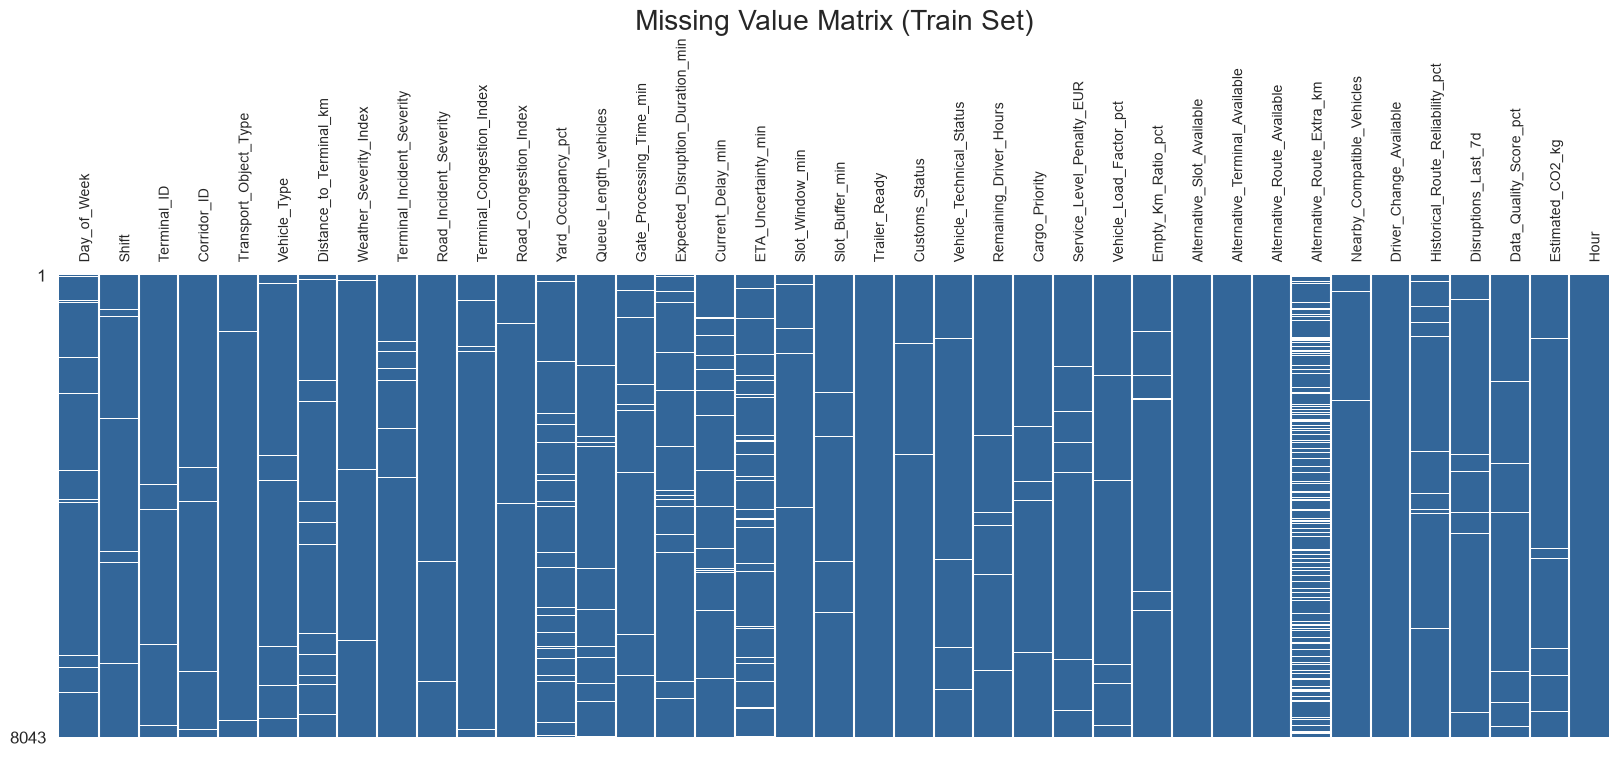

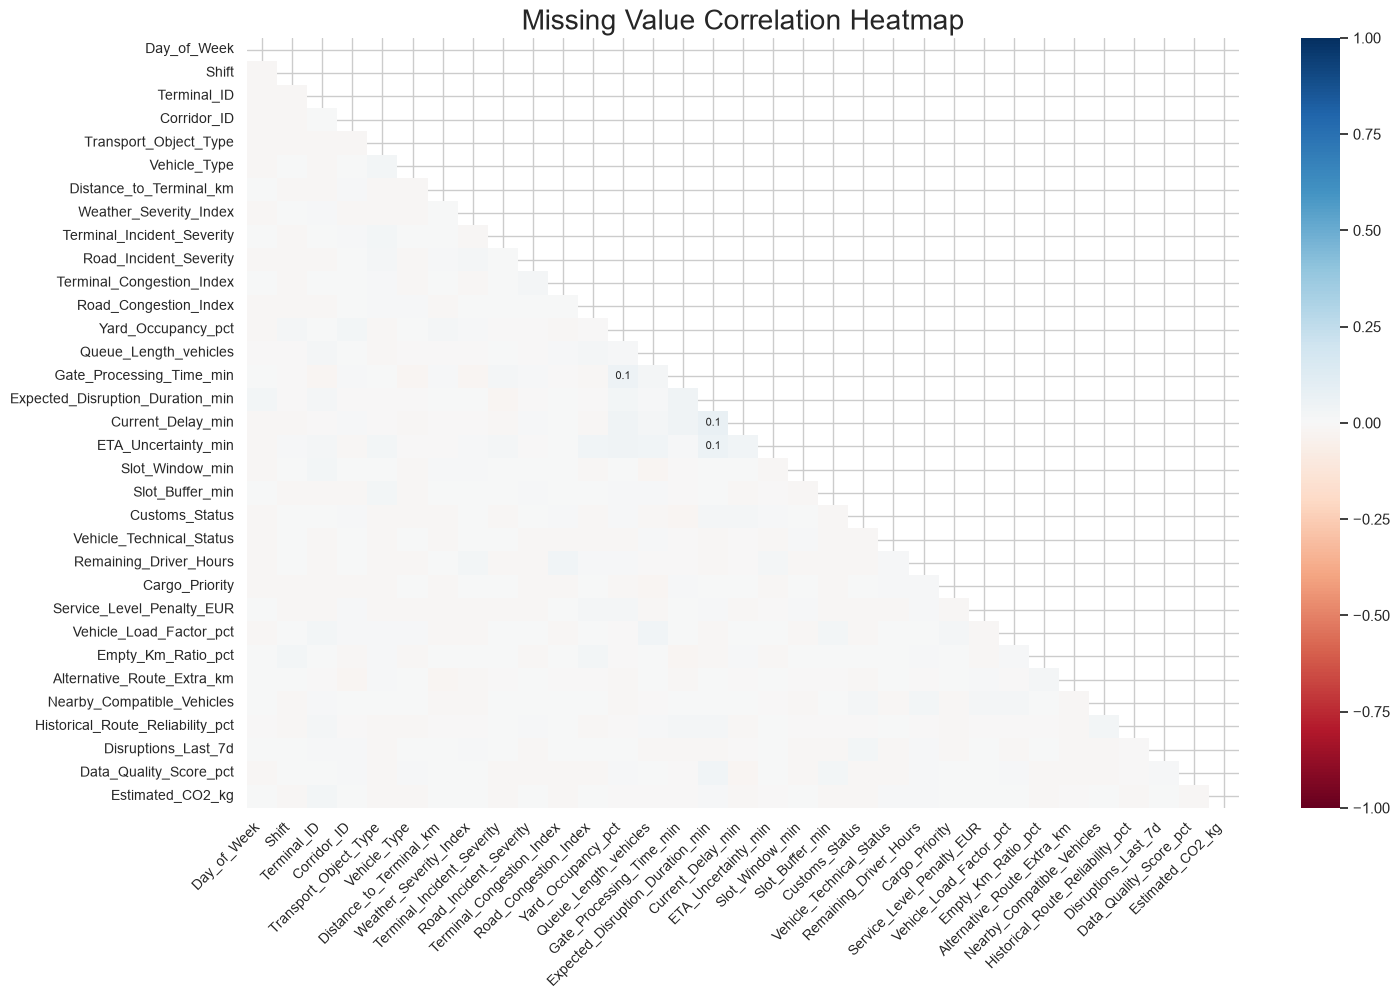

In [52]:
import matplotlib.pyplot as plt

# 1. Matrix plot (visualizes the location of missing values in the train set)
fig, ax = plt.subplots(figsize=(20, 6)) # Much wider canvas
msno.matrix(X_train, ax=ax, color=(0.2, 0.4, 0.6), fontsize=10)
plt.xticks(rotation=90) # Rotate labels to vertical
plt.title("Missing Value Matrix (Train Set)", fontsize=20)
plt.show()

# 2. Heatmap (shows if missingness in one column correlates with another)
fig, ax = plt.subplots(figsize=(16, 10)) 
msno.heatmap(X_train, ax=ax, fontsize=10)
plt.title("Missing Value Correlation Heatmap", fontsize=20)
plt.show()

### Define the Missing Data Types (MCAR, MAR, and MNAR)

From the missingno matrix, the nullity correlation heatmap, and the EDA, the mechanisms of missingness in this dataset can be categorized into:

**1. Missing at Random (MAR)**
*   **Mechanism:** The probability of missingness depends on an observed variable. The column `Alternative_Route_Extra_km` is 21.5% missing, and is structurally classified as MAR. The feature dictionary states very clearly that this column is "Blank when no alternative route exists." Before splitting the data, checks have established that this column is missing exactly when `Alternative_Route_Available == False`. The missingness is entirely explained by another recorded feature.

**2. Missing Completely at Random (MCAR)**
*   **Mechanism:** The missingness is independent of the data, both observed and unobserved data, and is completely random.
*   All remaining columns (e.g., `ETA_Uncertainty_min` at 5.66%, `Yard_Occupancy_pct` at 4.44%, and various sensor/categorical columns at ~1%) exhibit a scattered pattern in the matrix plot. The nullity correlation heatmap shows a nearly completely white image, where the correlation is 0.0, implying that the missingness of one column can inform us nothing about the missingness of another column. 
*   The only exceptions are a few delay-related metrics (`Current_Delay_min`, `Expected_Disruption_Duration_min`, `ETA_Uncertainty_min`) which show a negligible nullity correlation of 0.1. However, the correlation is too weak to suggest a systemic MAR pattern. So we label the remaining missingness as MCAR. 
*   Again, the statistical evidence supports the MCAR classification.

**3. Missing Not at Random (MNAR)**
*   **Mechanism:** The probability of missingness depends on the unobserved (unreported) missing value (e.g., very long delays that are not reported).
*   We found no evidence of MNAR in this dataset. There is no logical or statistical reason to believe that the missing values are the direct cause of their own absence. (i.e. unreported intentionally)

Since the missingness is either MAR (structurally dependent on a known flag) or MCAR (random dropouts), we can safely proceed with statistical imputation without introducing severe bias into the dataset.

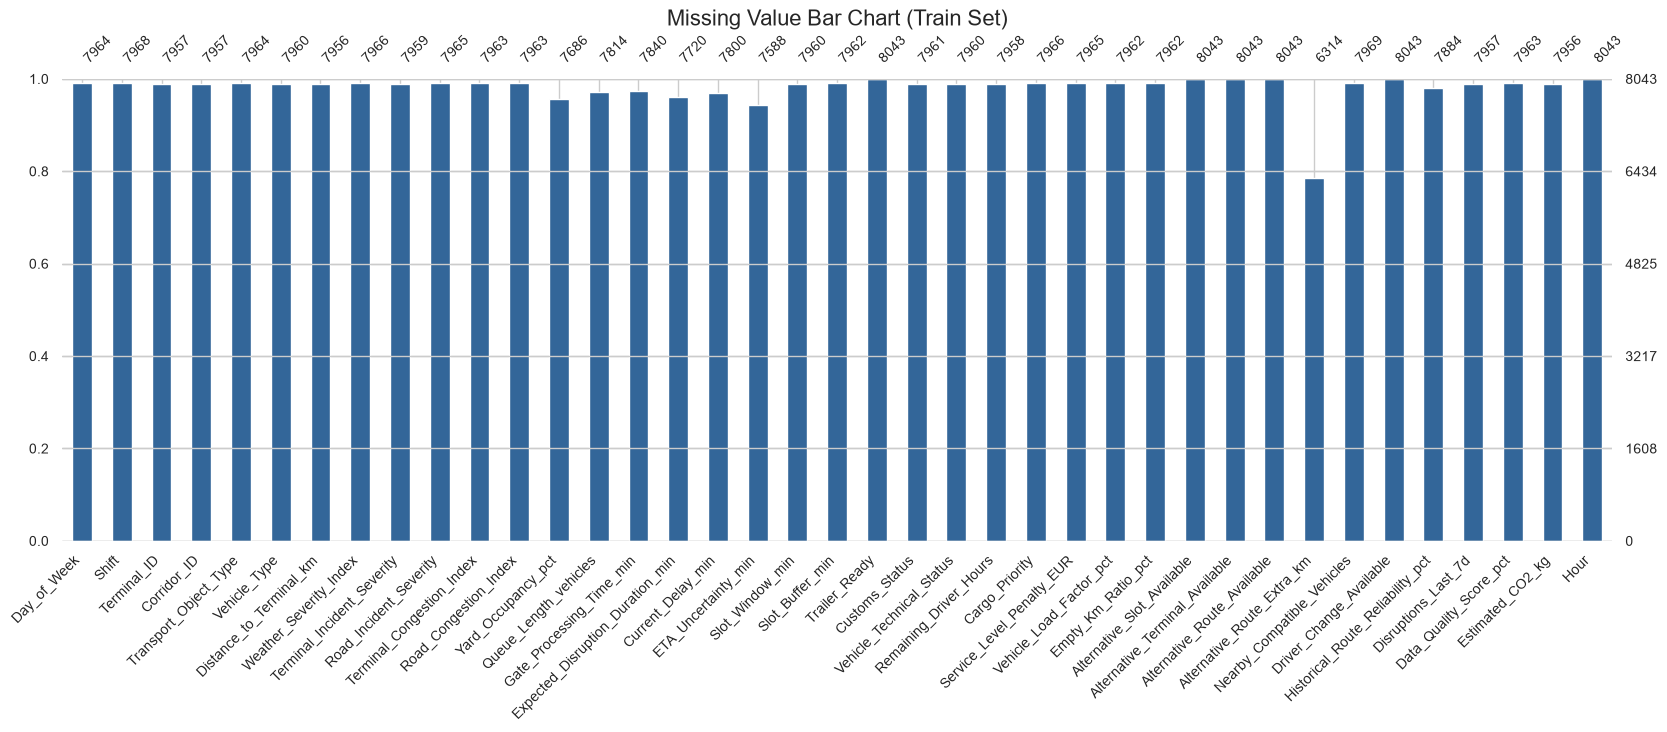

In [53]:
fig, ax = plt.subplots(figsize=(20, 6))
msno.bar(X_train, ax=ax, color=(0.2, 0.4, 0.6), fontsize=10)
plt.title("Missing Value Bar Chart (Train Set)", fontsize=16)
plt.show()

The bar chart above visualizes and confirms the missingness ratios per column findings that we identified
using pandas.

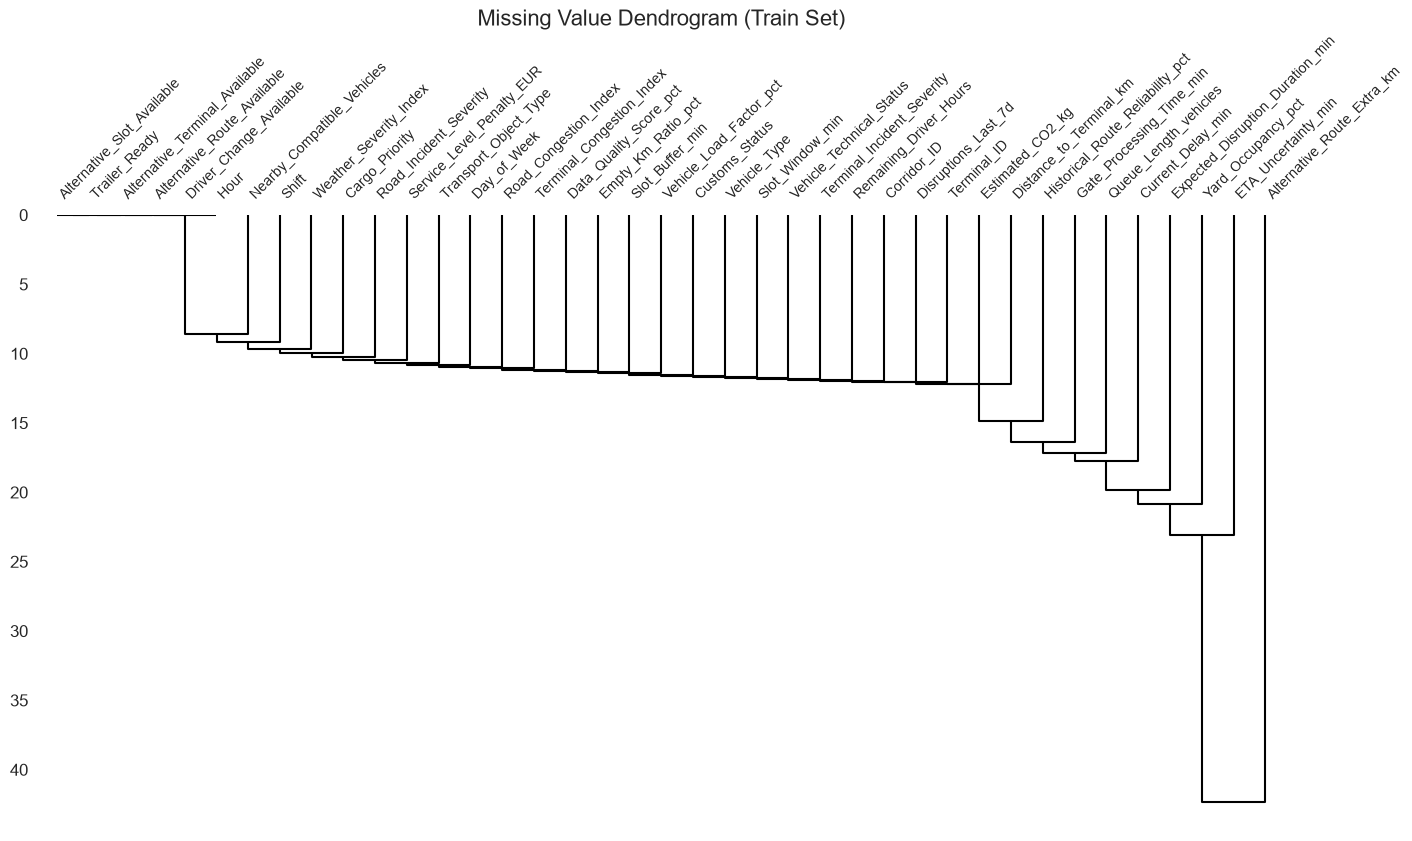

In [54]:
# 2. Dendrogram (shows how missingness clusters across columns)
fig, ax = plt.subplots(figsize=(16, 8))
msno.dendrogram(X_train, ax=ax, fontsize=10)
plt.title("Missing Value Dendrogram (Train Set)", fontsize=16)
plt.show()

the dendrogram above shows how missingness clusters across columns

# Statistical Measurement Scales of Dataset Features

To determine the correct encoding and scaling techniques, we classify the dataset features according to their statistical measurement scale:

**1. Nominal Variables (Unordered Categories)**
These variables represent distinct categories with no inherent mathematical order. They will require One-Hot Encoding.
*   **Categorical:** `Day_of_Week`, `Shift`, `Terminal_ID`, `Corridor_ID`, `Transport_Object_Type`, `Vehicle_Type`, `Customs_Status`.
*   **Target Variable:** `Recommended_Dispatch_Action`. 
*   **Boolean Flags (Binary Nominal):** `Trailer_Ready`, `Alternative_Slot_Available`, `Alternative_Terminal_Available`, `Alternative_Route_Available`, `Driver_Change_Available`.

**2. Ordinal Variables (Ordered Categories)**
These variables do have an obvious, meaningful rank or ordering, but the distances between the ranks are not necessarily equal. So, we will use Ordinal Encoding.
*   `Cargo_Priority` (1 = Normal, 2 = Elevated, 3 = High).
*   `Terminal_Incident_Severity` (0 = None to 3 = Severe).
*   `Road_Incident_Severity` (0 = None to 3 = Severe).
*   `Vehicle_Technical_Status` (OK < Warning < Critical).

**3. Ratio Variables (Continuous / Discrete Numeric)** 
These variables have a true zero point and equal distances between intervals. These are the only variables that will undergo Feature Scaling.
*   **Distance & Physical:** `Distance_to_Terminal_km`, `Alternative_Route_Extra_km`. 
*   **Time (Minutes/Hours):** `Gate_Processing_Time_min`, `Expected_Disruption_Duration_min`, `Current_Delay_min`, `ETA_Uncertainty_min`, `Slot_Window_min`, `Slot_Buffer_min`, `Remaining_Driver_Hours`.
*   **Counts:** `Queue_Length_vehicles`, `Nearby_Compatible_Vehicles`, `Disruptions_Last_7d`. 
*   **Indices & Percentages (0-100):** `Weather_Severity_Index`, `Terminal_Congestion_Index`, `Road_Congestion_Index`, `Yard_Occupancy_pct`, `Vehicle_Load_Factor_pct`, `Empty_Km_Ratio_pct`, `Historical_Route_Reliability_pct`, `Data_Quality_Score_pct`.
*   **Financial & Environmental Variables:** `Service_Level_Penalty_EUR`, `Estimated_CO2_kg`.

Note that there are no interval variables with arbitrary zero points in the dataset. Variables that are considered interval variables in other domains, e.g., timestamps, are actually already broken down in the feature engineering process.

## Implement Gower Distance-Based KNN Imputer

In [55]:
import numpy as np
import pandas as pd

# ============================================================
# 0. CONFIGURATION
# ============================================================

K = 5
CHUNK_SIZE = 256

STRUCTURAL_COL = "Alternative_Route_Extra_km"
ROUTE_FLAG_COL = "Alternative_Route_Available"

# Columns excluded from the Gower distance calculation
EXCLUDE_FROM_DISTANCE = [
    "Recommended_Dispatch_Action"
]

# Integer count variables: rounded mean.
COUNT_COLS = [
    "Queue_Length_vehicles",
    "Nearby_Compatible_Vehicles",
    "Disruptions_Last_7d"
]

# Numerical variables with restricted valid choices: mode.
RESTRICTED_NUMERIC_VALUES = {
    "Slot_Window_min": [30, 45, 60, 90]
}

# Ordinal variables.
ORDINAL_COLS = [
    "Cargo_Priority",
    "Terminal_Incident_Severity",
    "Road_Incident_Severity",
    "Vehicle_Technical_Status"
]

# Explicit ordinal category ordering.
ORDINAL_LEVELS = {
    "Cargo_Priority": [1, 2, 3],
    "Terminal_Incident_Severity": [0, 1, 2, 3],
    "Road_Incident_Severity": [0, 1, 2, 3],
    "Vehicle_Technical_Status": [
        "OK",
        "Warning",
        "Critical"
    ]
}

# No integer-coded nominal variables identified.
INTEGER_NOMINAL_COLS = []


# ============================================================
# 1. COPY DATA AND BASIC VALIDATION
# ============================================================

X_train = X_train.copy(deep=True)
X_test = X_test.copy(deep=True)

X_train_before_imputation = X_train.copy(deep=True)
X_test_before_imputation = X_test.copy(deep=True)

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("X_train and X_test must have identical columns.")

if not X_train.index.is_unique or not X_test.index.is_unique:
    raise ValueError("Dataset indices must be unique.")

if K < 1 or CHUNK_SIZE < 1:
    raise ValueError("K and CHUNK_SIZE must be at least 1.")

# Check required configuration columns.
configured_cols = (
    [STRUCTURAL_COL, ROUTE_FLAG_COL]
    + COUNT_COLS
    + list(RESTRICTED_NUMERIC_VALUES)
    + ORDINAL_COLS
    + INTEGER_NOMINAL_COLS
)

missing_config_cols = [col for col in configured_cols if col not in X_train.columns]
if missing_config_cols:
    raise ValueError(f"Configured columns not found: {missing_config_cols}")

# Excluded columns are retained in the output, but never used to calculate Gower distances.
DISTANCE_COLS = [col for col in X_train.columns if col not in EXCLUDE_FROM_DISTANCE]

excluded_present = [col for col in EXCLUDE_FROM_DISTANCE if col in X_train.columns]
for col in excluded_present:
    if X_train[col].isna().any() or X_test[col].isna().any():
        raise ValueError(f"Missing values found in excluded column '{col}'. Handle this column separately.")


# ============================================================
# 2. STRUCTURAL ZERO IMPUTATION
# ============================================================

for dataset in [X_train, X_test]:
    # No alternative route means additional route distance = 0.
    structural_mask = (
        dataset[STRUCTURAL_COL].isna()
        & dataset[ROUTE_FLAG_COL].eq(False)
    )
    dataset.loc[structural_mask, STRUCTURAL_COL] = 0

    # Validate the business rule.
    invalid = (
        dataset[ROUTE_FLAG_COL].eq(False)
        & dataset[STRUCTURAL_COL].notna()
        & dataset[STRUCTURAL_COL].ne(0)
    )
    if invalid.any():
        raise ValueError(f"Nonzero {STRUCTURAL_COL} found when {ROUTE_FLAG_COL} is False.")

print("Structural zero treatment completed.")


# ============================================================
# 3. IDENTIFY COLUMNS REQUIRING IMPUTATION
# ============================================================

cols_to_impute = [
    col for col in DISTANCE_COLS
    if X_train[col].isna().any() or X_test[col].isna().any()
]

print(f"Number of feature columns requiring imputation: {len(cols_to_impute)}")


# ============================================================
# 4. IDENTIFY FEATURE TYPES
# ============================================================

def is_numeric_feature(series):
    return (
        pd.api.types.is_numeric_dtype(series)
        and not pd.api.types.is_bool_dtype(series)
    )

numeric_cols = [
    col for col in DISTANCE_COLS
    if is_numeric_feature(X_train[col])
    and col not in ORDINAL_COLS
    and col not in INTEGER_NOMINAL_COLS
]

# Validate numerical count and restricted-choice variables.
for col in COUNT_COLS + list(RESTRICTED_NUMERIC_VALUES):
    if col not in numeric_cols:
        raise TypeError(f"{col} must be a numerical feature.")

# Convert numerical columns to float where necessary.
for col in numeric_cols:
    if col in cols_to_impute:
        X_train[col] = pd.to_numeric(X_train[col], errors="coerce").astype(float)
        X_test[col] = pd.to_numeric(X_test[col], errors="coerce").astype(float)


# ============================================================
# 5. PREPARE ORDINAL CATEGORY MAPPINGS
# ============================================================

ordinal_maps = {}

for col in ORDINAL_COLS:
    levels = ORDINAL_LEVELS[col]
    if len(levels) < 2 or len(set(levels)) != len(levels):
        raise ValueError(f"Invalid levels for ordinal column '{col}'.")

    ordinal_maps[col] = {value: rank for rank, value in enumerate(levels)}

    # Validate observed categories against the defined order.
    for dataset_name, dataset in [("Train", X_train), ("Test", X_test)]:
        observed_values = dataset[col].dropna().unique()
        unknown = [value for value in observed_values if value not in ordinal_maps[col]]
        if unknown:
            raise ValueError(f"Unexpected ordinal values in {dataset_name} for {col}: {unknown}")


# ============================================================
# 6. VALIDATE NUMERICAL VALUES
# ============================================================

for col in numeric_cols:
    for dataset_name, dataset in [("Train", X_train), ("Test", X_test)]:
        values = pd.to_numeric(dataset[col], errors="coerce").to_numpy(dtype=float)
        if np.isinf(values).any():
            raise ValueError(f"Infinite values detected in {col} ({dataset_name}).")


# ============================================================
# 7. LEARN NUMERICAL RANGES FROM TRAINING DATA ONLY
# ============================================================

ranges = {}

for col in numeric_cols:
    values = pd.to_numeric(X_train[col], errors="coerce").to_numpy(dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        raise ValueError(f"No observed training values available for {col}.")
    ranges[col] = values.max() - values.min()


# ============================================================
# 8. MANUAL GOWER DISTANCE CALCULATION
# ============================================================

def gower_distance(target, reference):
    n_target = len(target)
    n_reference = len(reference)

    total_distance = np.zeros((n_target, n_reference), dtype=float)
    valid_comparisons = np.zeros((n_target, n_reference), dtype=float)

    for col in DISTANCE_COLS:
        # A. NUMERICAL FEATURES
        if col in numeric_cols:
            t = pd.to_numeric(target[col], errors="coerce").to_numpy(dtype=float)
            r = pd.to_numeric(reference[col], errors="coerce").to_numpy(dtype=float)
            valid = np.isfinite(t[:, None]) & np.isfinite(r[None, :])
            feature_range = ranges[col]

            if feature_range > 0:
                d = np.abs(t[:, None] - r[None, :]) / feature_range
                d = np.clip(d, 0, 1)
            else:
                d = np.zeros((n_target, n_reference), dtype=float)

        # B. ORDINAL FEATURES
        elif col in ordinal_maps:
            mapping = ordinal_maps[col]
            t = target[col].map(mapping).to_numpy(dtype=float)
            r = reference[col].map(mapping).to_numpy(dtype=float)
            valid = np.isfinite(t[:, None]) & np.isfinite(r[None, :])
            max_difference = len(mapping) - 1
            d = np.abs(t[:, None] - r[None, :]) / max_difference

        # C. NOMINAL AND BOOLEAN FEATURES
        else:
            t_missing = target[col].isna().to_numpy()
            r_missing = reference[col].isna().to_numpy()
            combined = pd.concat([target[col].reset_index(drop=True), reference[col].reset_index(drop=True)], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=False)
            t_codes = codes[:n_target]
            r_codes = codes[n_target:]
            d = (t_codes[:, None] != r_codes[None, :]).astype(float)
            valid = ~(t_missing[:, None] | r_missing[None, :])

        total_distance += np.where(valid, d, 0)
        valid_comparisons += valid.astype(float)

    return np.divide(
        total_distance,
        valid_comparisons,
        out=np.full_like(total_distance, np.inf),
        where=valid_comparisons > 0
    )


# ============================================================
# 9. IMPUTATION VALUE RULES
# ============================================================

def calculate_imputation_value(neighbor_values, col):
    neighbor_values = neighbor_values.dropna()
    if neighbor_values.empty:
        raise ValueError(f"No observed neighbor values for {col}.")

    if col in RESTRICTED_NUMERIC_VALUES:
        value = neighbor_values.mode().iloc[0]
        allowed = RESTRICTED_NUMERIC_VALUES[col]
        if value not in allowed:
            raise ValueError(f"Invalid imputed value {value} for {col}.")
        return value

    if col in COUNT_COLS:
        return int(np.rint(neighbor_values.mean()))

    if col in numeric_cols:
        return float(neighbor_values.mean())

    return neighbor_values.mode().iloc[0]


# ============================================================
# 10. FALLBACK RULES
# ============================================================

def calculate_fallback(reference, col):
    observed = reference[col].dropna()
    if observed.empty:
        raise ValueError(f"No observed training values available for {col}.")

    if col in RESTRICTED_NUMERIC_VALUES:
        return observed.mode().iloc[0]
    if col in COUNT_COLS:
        return int(np.rint(observed.median()))
    if col in numeric_cols:
        return float(observed.median())
    return observed.mode().iloc[0]


# ============================================================
# 11. IMPUTE ONE COLUMN
# ============================================================

def impute_column(dataset, col, target_source, reference, k=K, chunk_size=CHUNK_SIZE):
    missing_positions = np.flatnonzero(target_source[col].isna().to_numpy())
    if len(missing_positions) == 0:
        return 0

    reference_positions = np.flatnonzero(reference[col].notna().to_numpy())
    if len(reference_positions) == 0:
        raise ValueError(f"No observed training reference values for {col}.")

    ref = reference.iloc[reference_positions].copy()
    fallback = calculate_fallback(ref, col)
    fallback_count = 0
    col_position = dataset.columns.get_loc(col)

    for start in range(0, len(missing_positions), chunk_size):
        batch_positions = missing_positions[start:start + chunk_size]
        target = target_source.iloc[batch_positions].copy()
        distances = gower_distance(target, ref)

        for i, row_position in enumerate(batch_positions):
            valid_positions = np.flatnonzero(np.isfinite(distances[i]))
            if len(valid_positions) == 0:
                imputed_value = fallback
                fallback_count += 1
            else:
                ordered_positions = valid_positions[np.argsort(distances[i, valid_positions], kind="stable")]
                nearest_positions = ordered_positions[:k]
                neighbor_values = ref.iloc[nearest_positions][col]

                if neighbor_values.dropna().empty:
                    imputed_value = fallback
                    fallback_count += 1
                else:
                    imputed_value = calculate_imputation_value(neighbor_values, col)

            dataset.iat[row_position, col_position] = imputed_value

    return fallback_count


# ============================================================
# 12. CREATE IMMUTABLE ORIGINAL SNAPSHOTS
# ============================================================

X_train_reference = X_train.copy(deep=True)
X_test_reference = X_test.copy(deep=True)


# ============================================================
# 13. IMPUTE TRAINING AND TEST DATA
# ============================================================

print("\nStarting Gower-KNN imputation...")
train_fallbacks, test_fallbacks = {}, {}

for col in cols_to_impute:
    train_fallbacks[col] = impute_column(X_train, col, X_train_reference, X_train_reference, K)

for col in cols_to_impute:
    test_fallbacks[col] = impute_column(X_test, col, X_test_reference, X_train_reference, K)


# ============================================================
# 14. RESTORE INTEGER DTYPES WHERE APPROPRIATE
# ============================================================

INTEGER_ORDINAL_COLS = ["Cargo_Priority", "Terminal_Incident_Severity", "Road_Incident_Severity"]
integer_cols = COUNT_COLS + list(RESTRICTED_NUMERIC_VALUES) + INTEGER_ORDINAL_COLS

for col in integer_cols:
    for dataset in [X_train, X_test]:
        if dataset[col].isna().any(): continue
        values = dataset[col].to_numpy(dtype=float)
        if np.allclose(values, np.round(values)):
            dataset[col] = pd.array(np.round(values).astype(int), dtype="Int64")


# ============================================================
# 15. FINAL VALIDATION
# ============================================================

print("\n" + "=" * 65)
print("GOWER-KNN IMPUTATION SUMMARY")
print("=" * 65)

print(f"Remaining missing values in X_train: {X_train.isna().sum().sum()}")
print(f"Remaining missing values in X_test: {X_test.isna().sum().sum()}")

# Final assertions
if X_train.isna().any().any() or X_test.isna().any().any():
    raise ValueError("Imputation incomplete: missing values remain.")

print("\nAll imputation and validation checks passed.")
print("Final feature dimensions:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Structural zero treatment completed.
Number of feature columns requiring imputation: 32

Starting Gower-KNN imputation...

GOWER-KNN IMPUTATION SUMMARY
Remaining missing values in X_train: 0
Remaining missing values in X_test: 0

All imputation and validation checks passed.
Final feature dimensions:
X_train: (8043, 39)
X_test: (2011, 39)


### Reasoning for Choosing the Gower Distance-Based KNN Imputation Technique

After examining the missing-data patterns and the characteristics of the Port Logistics Dispatching dataset, we selected **Gower distance-based K-Nearest Neighbors (KNN) imputation** as our primary method for handling statistical missing values. In addition, we applied a separate logical zero-imputation rule to `Alternative_Route_Extra_km`, where missing values represent structural absence rather than unknown measurements.

#### Why Other Imputation Approaches Were Not Selected

Several alternative approaches were considered:

- **Row deletion:** Removing observations containing missing values would result in unnecessary information loss. This is particularly relevant for `Alternative_Route_Extra_km`, where approximately 21.6% of the observations are missing because an alternative route is unavailable. These values are not genuinely unknown and should therefore not lead to the removal of otherwise valid observations.

- **Forward/backward filling and interpolation:** These techniques are more appropriate for sequential or time-dependent observations. Our dataset consists of individual logistics events rather than a continuous time series in which consecutive observations necessarily share a meaningful relationship. Consequently, transferring values between adjacent rows would not be methodologically justified.

- **Simple statistical imputation:** Replacing missing values with global means, medians, or modes would ignore the multivariate characteristics of the observations. Such an approach could overlook similarities between logistics events and potentially distort the underlying feature distributions.

- **Iterative imputation:** Iterative imputation estimates missing values by modelling each incomplete feature as a function of the remaining features. Its effectiveness therefore depends on the relationships captured by the underlying estimators. With conventional linear estimators, this approach primarily captures linear relationships unless more flexible, nonlinear estimators are explicitly selected. However, our exploratory analysis suggested that the relationships within the dataset are not necessarily well represented by simple linear dependencies. Furthermore, the heterogeneous nature of the features makes a unified distance-based approach particularly attractive. We therefore preferred Gower distance-based KNN, which identifies locally similar observations without requiring the relationships between features to be represented through a set of fitted conditional prediction models.

#### Why Gower Distance-Based KNN?

The main reason for selecting Gower distance is the heterogeneous nature of our dataset. It contains numerical, nominal, ordinal, and Boolean variables, making a distance measure designed for mixed data types particularly appropriate.

Unlike conventional Euclidean distance, Gower distance allows different feature types to contribute to the similarity calculation according to their nature:

- **Numerical features:** Differences are normalized by the corresponding feature ranges, ensuring that variables measured on different scales can contribute comparably to the distance calculation.
- **Nominal and Boolean features:** Similarity is determined through a simple match(matched categories implies that gower distance is 0) or mismatch (unmatched categories implies that gower distance is 1) comparison.
- **Ordinal features:** Categories are assigned their predefined natural ordering, and differences are calculated using normalized rank distances. This preserves ordering information rather than treating ordinal categories as unrelated nominal labels.

Using this distance measure, KNN identifies the five most similar observations for each missing value. The imputation itself then follows feature-specific rules to preserve the nature and valid representation of each variable:

- Continuous numerical features are imputed using the mean of the five nearest neighbors.
- Integer count variables are imputed using the rounded mean of the five nearest neighbors.
- Nominal, ordinal, and Boolean features are imputed using the mode of the five nearest neighbors.
- `Slot_Window_min`, which has a restricted set of valid numerical choices (30, 45, 60, and 90 minutes), is imputed using the mode to ensure that the resulting value remains within its predefined valid choices.

We fixed the number of neighbors at **K = 5**, providing a reasonable compromise between relying on sufficiently local observations and reducing sensitivity to individual neighbors.

Importantly, Gower distance is used to identify similar observations, whereas the imputation statistic is selected separately according to the feature type. This distinction ensures that ordinal and categorical variables retain valid category values rather than receiving artificial numerical estimates.

#### Treatment of Structural Missingness

A specific rule was applied to `Alternative_Route_Extra_km`.

The exploratory analysis established that its missing values correspond to observations where `Alternative_Route_Available` is `False`. From a logistics perspective, when no alternative route is available, the additional distance associated with such a route is logically zero.

Therefore, these missing values were replaced with zero rather than estimated through KNN. This preserves the underlying operational meaning of the feature and avoids introducing artificial distances.

If an alternative route were available but its additional distance were missing, that would represent a genuinely unknown measurement and would be eligible for statistical imputation. The distinction between these two situations is therefore maintained explicitly in the implementation.

#### Avoiding Data Leakage

To preserve the integrity of the train/test split, the imputation procedure was designed to avoid information leakage.

Numerical feature ranges used in the Gower distance calculation were learned exclusively from the training set. Furthermore, the original, unimputed training observations were retained as reference data throughout the process.

Missing values in the training set were imputed using the original training observations as reference, while missing values in the test set were imputed exclusively using the original training observations. The test set was therefore never used to derive numerical ranges or reference observations.

The prediction target, `Recommended_Dispatch_Action`, was also excluded from the Gower distance calculation to prevent target information from influencing the identification of nearest neighbors. The identifier and raw timestamp had already been removed before the train/test split, with the relevant temporal information extracted into `Hour`.

Overall, this approach provides a consistent treatment of mixed data types, accounts for local similarities between logistics events without imposing a global linear relationship, preserves the operational meaning of structurally missing values, and maintains a clear separation between training and test information.

#### Immutable Snapshots
A common pitfall in multivariate imputation is cascading error (also known as order-dependence). If we impute Column A, and then use those newly filled-in values to find neighbors for Column B, the second imputation relies on artificial data.

To prevent this, we take an immutable snapshot (X_train_reference) of the data right before imputation begins. All neighbor searches look exclusively at this frozen, original version. We save the imputed values to the active dataset, but we never use them as reference points for other columns. This guarantees that every missing value is filled based on the original data, completely independent of the column processing order.

Overall, this approach provides a consistent treatment of mixed data types, preserves the operational meaning of structurally missing values, and maintains a clear separation between training and test information

## Visualization of data before/after applying the imputation technique

#### Cell 0: check if missing values still exist on the training dataset first

In [56]:
# Check missing values across the entire training set
missing_train = X_train.isna().sum()

missing_train = missing_train[missing_train > 0].sort_values(ascending=False)

if missing_train.empty:
    print("Training set: No missing values remaining in any column.")
else:
    print("Columns with remaining missing values:")
    display(missing_train)

Training set: No missing values remaining in any column.


#### Cell 1: Numerical features (histograms)

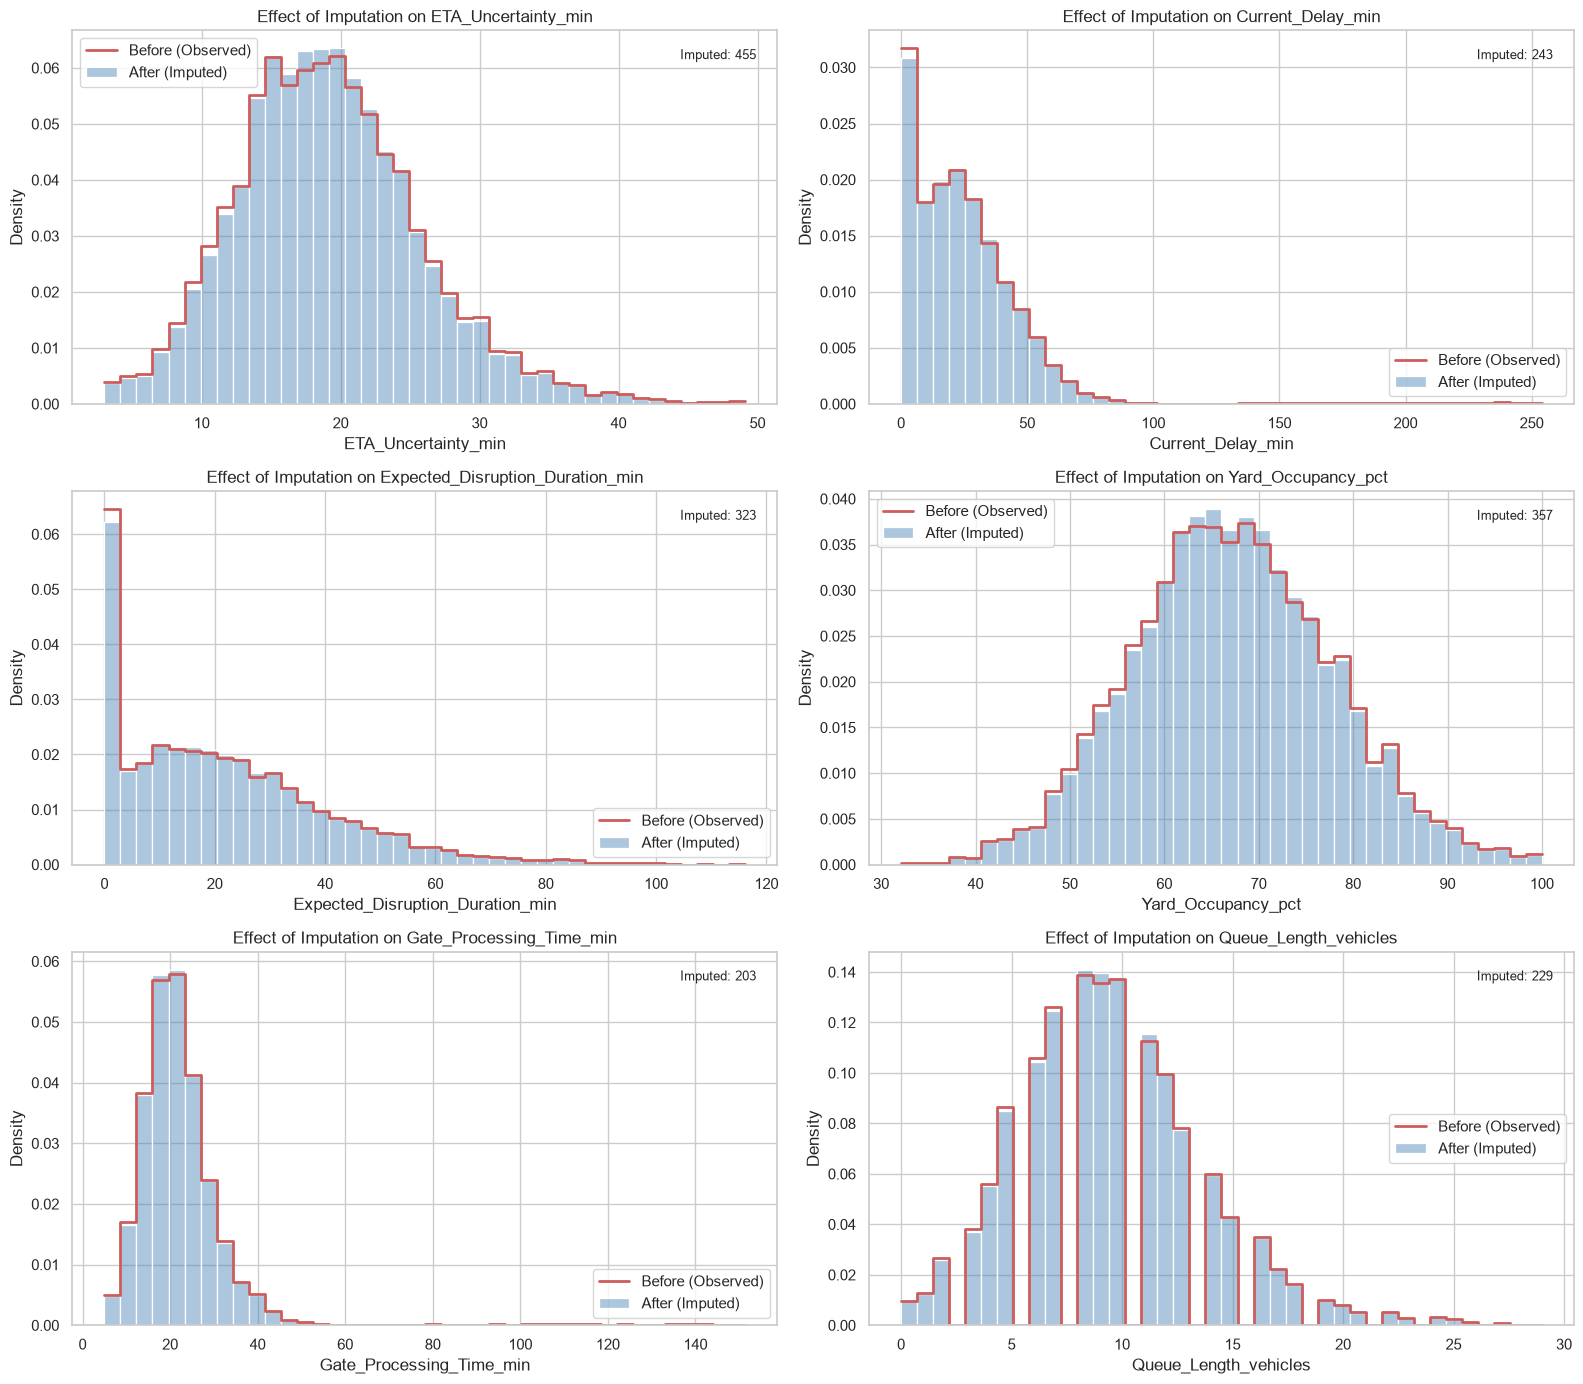

In [57]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cols_to_plot = [
    'ETA_Uncertainty_min',
    'Current_Delay_min',
    'Expected_Disruption_Duration_min',
    'Yard_Occupancy_pct',
    'Gate_Processing_Time_min',
    'Queue_Length_vehicles'
]

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):

    before = X_train_before_imputation[col].dropna()
    after = X_train[col]

    bins = np.histogram_bin_edges(
        np.concatenate([before, after]), bins=40
    )

    sns.histplot(
        after, bins=bins, stat="density",
        color="steelblue", alpha=0.45,
        label="After (Imputed)", ax=axes[i]
    )

    sns.histplot(
        before, bins=bins, stat="density",
        color="indianred", fill=False,
        element="step", linewidth=2,
        label="Before (Observed)", ax=axes[i]
    )

    axes[i].set_title(f"Effect of Imputation on {col}")
    axes[i].set_ylabel("Density")
    axes[i].legend()

    axes[i].text(
        0.97, 0.95,
        f"Imputed: {X_train_reference[col].isna().sum()}",
        transform=axes[i].transAxes,
        ha="right", va="top", fontsize=9
    )

plt.tight_layout()
plt.show()


Histograms show distributions of all selected numerical variables before and after Gower distance based KNN imputation. The red outlines show the originally observed values. The distributions after imputation are shown as the blue histograms.

Overall, the two distributions show a substantial overlap along the features chosen; the distributional shapes and the levels of concentration are only slightly different. This indicates that the imputation retained the distributional shape of the numerical variables to a great extent, without any visible distortions.

Small differences in density can be seen in some places, but these are to be expected when previously missing observations have been added to the distributions. Importantly, the overall patterns, including the right-skewness of `Current_Delay_min` and `Expected_Disruption_Duration_min` and the approximately bell-shaped distribution of `Yard_Occupancy_pct`, remain broadly consistent.

In general the visual comparison is reassuring that the selected imputation method has preserved the overall shape of the observed numerical data when filled in missing values.

#### Cell 2: Nominal and ordinal features (bar charts)

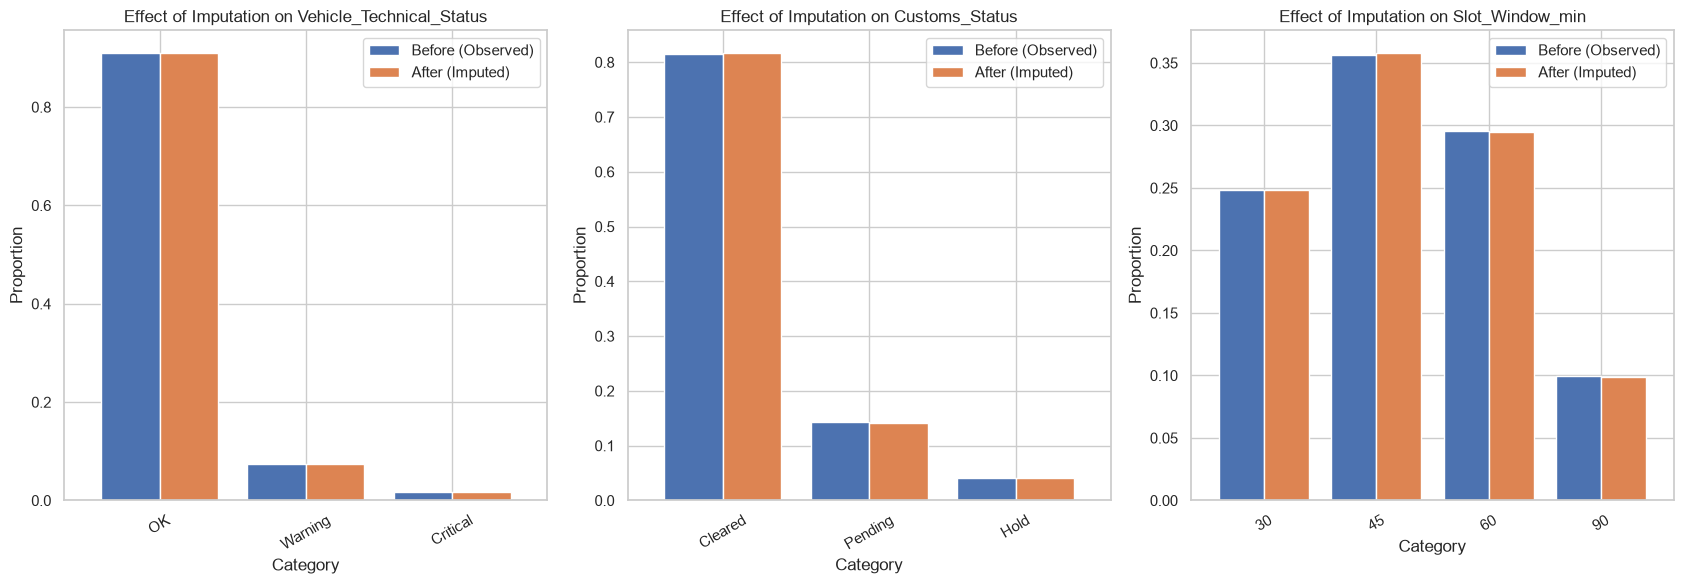

In [58]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

cols_to_plot = [
    'Vehicle_Technical_Status',
    'Customs_Status',
    'Slot_Window_min'
]

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

for i, col in enumerate(cols_to_plot):

    before = X_train_before_imputation[col].dropna()
    after = X_train[col].dropna()

    categories = (
        [30, 45, 60, 90]
        if col == 'Slot_Window_min'
        else list(pd.unique(pd.concat([before, after])))
    )

    before_prop = before.value_counts(normalize=True).reindex(
        categories, fill_value=0
    )

    after_prop = after.value_counts(normalize=True).reindex(
        categories, fill_value=0
    )

    comparison = pd.DataFrame({
        "Before (Observed)": before_prop,
        "After (Imputed)": after_prop
    })

    comparison.plot(kind="bar", ax=axes[i], width=0.8)

    axes[i].set_title(f"Effect of Imputation on {col}")
    axes[i].set_xlabel("Category")
    axes[i].set_ylabel("Proportion")
    axes[i].tick_params(axis="x", rotation=30)
    axes[i].legend()

plt.tight_layout()
plt.show()


The category distributions reveal a substantial overlap of original and imputed data, with the proportions of 'Vehicle_Technical_Status', 'Customs_Status' and 'Slot_Window_min' virtually unchanged after imputation. The results therefore indicate the mode based imputation with the five closest (by Gower distance) neighbors has preserved the original distribution of categories for the nominal and ordinal features well without greatly shifting the proportions. It is also worth noting that the imputation found valid predefined categories for all selected plotted three features.

#### Cell 3: Structural missingness (histogram)

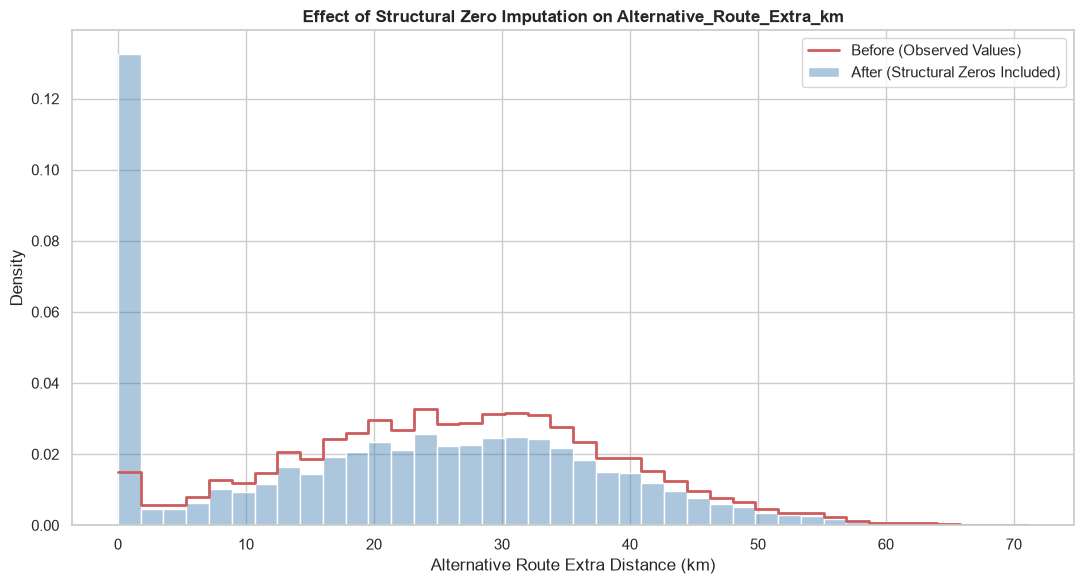

In [59]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

col = 'Alternative_Route_Extra_km'

before = X_train_before_imputation[col].dropna()
after = X_train[col].dropna()

bins = np.histogram_bin_edges(
    np.concatenate([before, after]), bins=40
)

plt.figure(figsize=(11, 6))

sns.histplot(
    after, bins=bins, stat="density",
    color="steelblue", alpha=0.45,
    label="After (Structural Zeros Included)"
)

sns.histplot(
    before, bins=bins, stat="density",
    color="indianred", fill=False,
    element="step", linewidth=2,
    label="Before (Observed Values)"
)

plt.title(
    "Effect of Structural Zero Imputation on Alternative_Route_Extra_km",
    fontweight="bold"
)
plt.xlabel("Alternative Route Extra Distance (km)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()


The "before-and-after" distributions illustrate the effect of replacing structurally missing values in 'Alternative_Route_Extra_km' with zero. These structurally missing values are those in which 'Alternative_Route_Available' is set to False which means that there was no alternative route. As a result, zero extra km becomes a sensible reflection of the actual state of operation and not a statistical estimate.

Once imputation is applied, a clear spike at zero is observed, corresponding to observations that lack an alternative route. The distribution of positive extra distances remains broadly consistent with the original distribution of observed data, but with a noticed reduction in the density caused by the values of zero added, because they contribute to the overall distribution.

Thus confirming that the structural missingness is taken into account in terms of its operational meaning, while maintaining the observed values of the feature.

# Part 4: Detecting and handling outliers


### **Detecing outliers using IQR**

#### Reasoning behind choosing IQR over other outlier detection techniques

This method was chosen because it is robust to skewed and non-normally distributed numerical data. The Z-score method, which depends on the mean and standard deviation for detection and is more sensitive to extreme observations, becomes less reliable for heavily skewed or on non-normally distributed data. Instead, this method (i.e. IQR) uses median-based quartiles to detect particularly extreme low or high observations.

This feature makes IQR a more appropriate measure for the Port Logistics Dispatching dataset, where some features of interest, for example `Current_Delay_min`, `Expected_Disruption_Duration_min`, and `Queue_Length_vehicles` may have skewed distributions and have natural outliers (extreme observations)

Potential outliers are identified using the usual lower and upper fences, defined as \(Q_1 - 1.5 \times IQR\) and \(Q_3 + 1.5 \times IQR\), respectively, where \(IQR = Q_3 - Q_1\).

Using Isolation forest as an alternative to IQR was also considered. Unlike IQR, which identifies extreme values independently within individual features, Isolation Forest detects anomalies based on combinations of feature values. While this multivariate anomaly-detection approach can be beneficial, particularly with large, high-dimensional, or complex datasets (e.g. sensor data with many measurements, or many interacting variables), it adds complexity and involves selecting parameters, e.g. anticipated contamination (proportion of samples that are anomalous). However, for the current EDA, where the main goal is to pinpoint and explore anomalies in single numerical features (univariate investigation), Isolation Forest’s multivariate anomaly-detection capability does not provide a necessary advantage over the more interpretable IQR approach.

As such, IQR was chosen on the basis of its simplicity, interpretability and its appropriateness given the data distribution.

Importantly, observations outside of these limits are considered to be potential outliers, rather than errors. In a logistics context, very long delays, long queues, or long disruption durations could be actual operational conditions that are pertinent for predicting dispatch decisions. Therefore, IQR stands out as the most suitable approach to identify these outliers and then proceed with investigation.

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude ordinal variables represented numerically
ordinal_numeric_cols = [
    "Cargo_Priority",
    "Terminal_Incident_Severity",
    "Road_Incident_Severity"
]

# Exclude restricted-value numerical variables
restricted_numeric_cols = [
    "Slot_Window_min"
]

excluded_numeric_cols = (
    ordinal_numeric_cols
    + restricted_numeric_cols
    + ["Hour"]
)

# Select all remaining numerical features
numerical_cols = [
    col for col in X_train.select_dtypes(include=np.number).columns
    if col not in excluded_numeric_cols
]

numerical_cols = [
    col for col in numerical_cols
    if col not in ordinal_numeric_cols + restricted_numeric_cols
]

print(f"Number of eligible numerical features: {len(numerical_cols)}")
print("\nFeatures selected:")
print(numerical_cols)

Number of eligible numerical features: 21

Features selected:
['Distance_to_Terminal_km', 'Weather_Severity_Index', 'Terminal_Congestion_Index', 'Road_Congestion_Index', 'Yard_Occupancy_pct', 'Queue_Length_vehicles', 'Gate_Processing_Time_min', 'Expected_Disruption_Duration_min', 'Current_Delay_min', 'ETA_Uncertainty_min', 'Slot_Buffer_min', 'Remaining_Driver_Hours', 'Service_Level_Penalty_EUR', 'Vehicle_Load_Factor_pct', 'Empty_Km_Ratio_pct', 'Alternative_Route_Extra_km', 'Nearby_Compatible_Vehicles', 'Historical_Route_Reliability_pct', 'Disruptions_Last_7d', 'Data_Quality_Score_pct', 'Estimated_CO2_kg']


The eligible numerical features were selected for IQR-based outlier detection, excluding ordinal, Boolean, categorical, restricted-value, and cyclic variables. Count and continuous numerical features were retained.

In [61]:
# Calculate quartiles using training data only
Q1 = X_train[numerical_cols].quantile(0.25)
Q3 = X_train[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

# Calculate IQR fences
lower_bounds = Q1 - 1.5 * IQR
upper_bounds = Q3 + 1.5 * IQR

# Detect potential outliers in training data
train_outlier_flags = (
    (X_train[numerical_cols] < lower_bounds) |
    (X_train[numerical_cols] > upper_bounds)
)

# Detect potential outliers in test data
test_outlier_flags = (
    (X_test[numerical_cols] < lower_bounds) |
    (X_test[numerical_cols] > upper_bounds)
)

# Create a summary table
outlier_summary = pd.DataFrame({
    "Train_Outliers": train_outlier_flags.sum(),
    "Train_Percentage (%)": (
        train_outlier_flags.mean() * 100
    ).round(2),
    "Test_Outliers": test_outlier_flags.sum(),
    "Test_Percentage (%)": (
        test_outlier_flags.mean() * 100
    ).round(2)
})

display(outlier_summary)

,Train_Outliers,Train_Percentage (%),Test_Outliers,Test_Percentage (%)
Distance_to_Terminal_km,472,5.87,127,6.32
Weather_Severity_Index,322,4.0,58,2.88
Terminal_Congestion_Index,58,0.72,9,0.45
Road_Congestion_Index,0,0.0,0,0.0
Yard_Occupancy_pct,62,0.77,13,0.65
Queue_Length_vehicles,165,2.05,37,1.84
Gate_Processing_Time_min,266,3.31,65,3.23
Expected_Disruption_Duration_min,163,2.03,36,1.79
Current_Delay_min,139,1.73,33,1.64
ETA_Uncertainty_min,135,1.68,30,1.49


The IQR analysis identified potential outliers across several numerical features, with the highest proportions observed in `Service_Level_Penalty_EUR`, `Distance_to_Terminal_km`, and `Estimated_CO2_kg`. No flagged observations in selected features mean the feature values are within the computed IQR fences. These observations (i.e. the numerical features with existing outliers) are not rejected automatically but are identified for further review.

#### visualize potential outliers (detected by IQR approach) across all numerical features

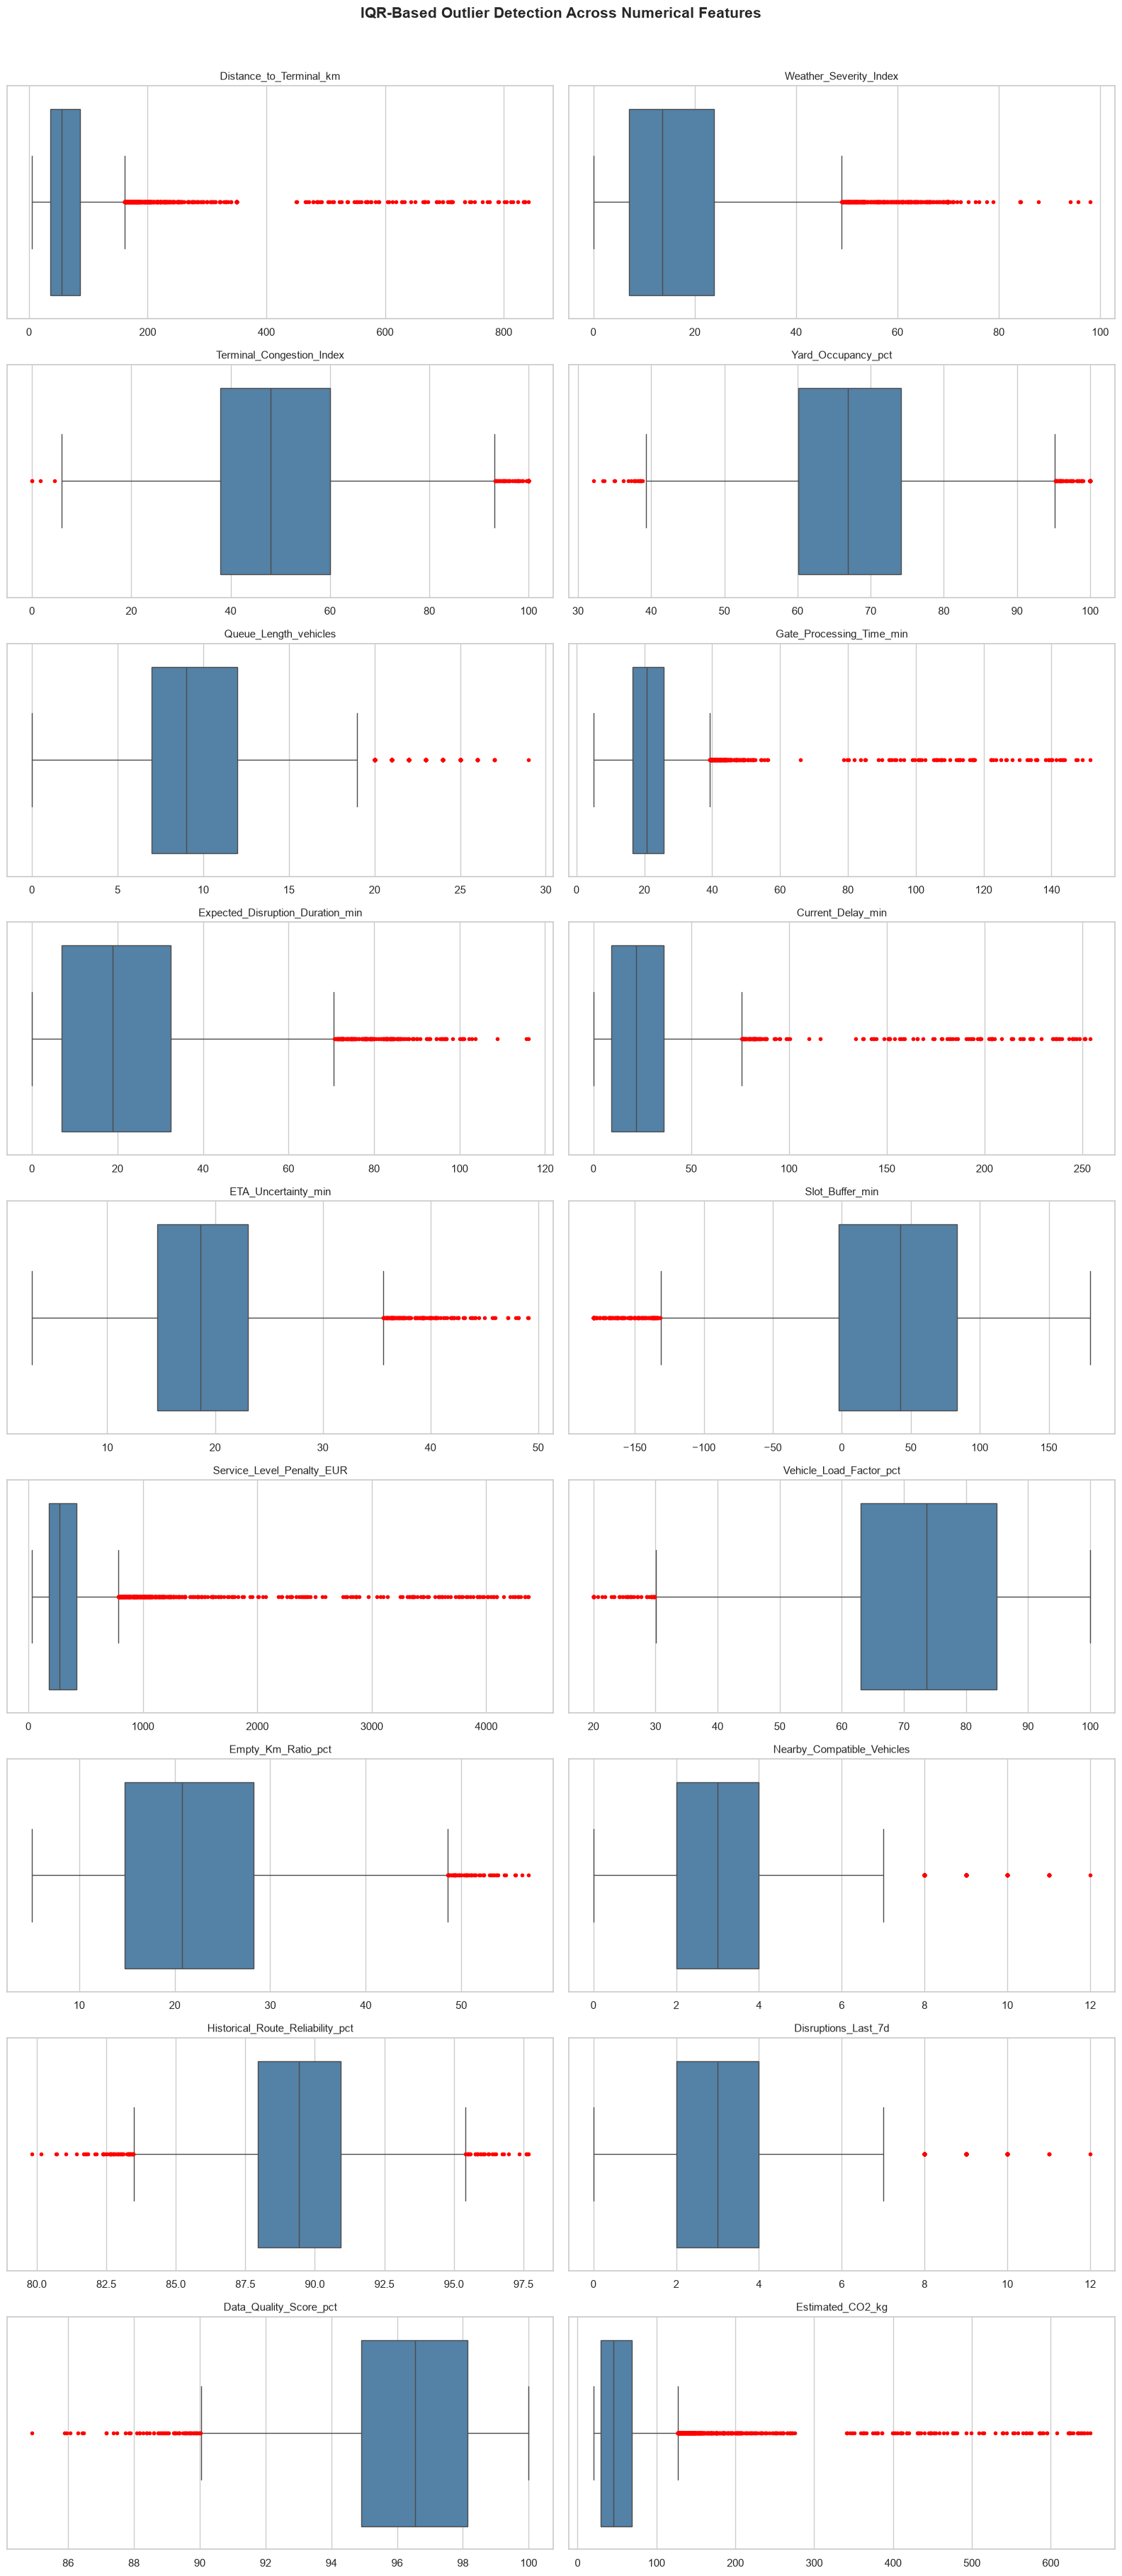

In [62]:

sns.set_theme(style="whitegrid")

# Exclude features with zero detected outliers from visualization
features_to_plot = [
    col for col in numerical_cols
    if train_outlier_flags[col].sum() > 0
]

n_cols = 2
n_rows = int(np.ceil(len(features_to_plot) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(16, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(features_to_plot):

    sns.boxplot(
        x=X_train[col],
        ax=axes[i],
        color="steelblue",
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "red",
            "markeredgecolor": "red"
        }
    )

    axes[i].set_title(f"{col}", fontsize=11)
    axes[i].set_xlabel("")

# Remove unused subplot axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "IQR-Based Outlier Detection Across Numerical Features",
    fontsize=15,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()


The boxplots reveal possible outliers in many of the numerical features, with very long upper tails for example for features like 'Distance_to_Terminal_km', 'Gate_Processing_Time_min', 'Current_Delay_min', 'Service_Level_Penalty_EUR', and `Estimated_CO2_kg'. Some features also have potential outliers on either side of their distribution.

The results show that several variables (numeric) have outliers and have an asymmetric distribution. Operationally speaking, these outliers can probably reflect relevant logistics conditions to consider, and may protentially not be anomalies. Therefore, there is no need to eliminate or adjust them automatically.

These boxplots provides the starting point for judging the effects of the subsequent outlier treatment.

### **Handling the Outliers**

#### Cell 1: Investigate the numerical columns with outliers (18)

In [63]:
# Investigate the 18 numerical features with detected outliers

features_to_investigate = [
    col for col in numerical_cols
    if train_outlier_flags[col].sum() > 0
]

investigation_results = []

for col in features_to_investigate:

    lower_values = X_train.loc[
        train_outlier_flags[col] & (X_train[col] < lower_bounds[col]),
        col
    ]

    upper_values = X_train.loc[
        train_outlier_flags[col] & (X_train[col] > upper_bounds[col]),
        col
    ]

    investigation_results.append({
        "Feature": col,
        "Lower_Fence": round(lower_bounds[col], 2),
        "Upper_Fence": round(upper_bounds[col], 2),
        "Minimum": round(X_train[col].min(), 2),
        "Maximum": round(X_train[col].max(), 2),
        "Lower_Outliers": len(lower_values),
        "Upper_Outliers": len(upper_values),
        "Lowest_Flagged": (
            round(lower_values.min(), 2)
            if not lower_values.empty else np.nan
        ),
        "Highest_Flagged": (
            round(upper_values.max(), 2)
            if not upper_values.empty else np.nan
        )
    })

investigation_summary = pd.DataFrame(investigation_results)

display(investigation_summary)


,Feature,Lower_Fence,Upper_Fence,Minimum,Maximum,Lower_Outliers,Upper_Outliers,Lowest_Flagged,Highest_Flagged
0,Distance_to_Terminal_km,-39.82,161.08,5.00,842.05,0,472,NaN,842.05
1,Weather_Severity_Index,-18.02,48.94,0.02,98.01,0,322,NaN,98.01
2,Terminal_Congestion_Index,4.83,93.17,0.00,100.00,4,54,0.00,100.00
3,Yard_Occupancy_pct,39.10,95.20,32.11,100.00,18,44,32.11,100.00
4,Queue_Length_vehicles,-0.50,19.50,0.00,29.00,0,165,NaN,29.00
5,Gate_Processing_Time_min,2.94,39.31,5.00,151.38,0,266,NaN,151.38
6,Expected_Disruption_Duration_min,-31.40,70.65,0.00,116.16,0,163,NaN,116.16
7,Current_Delay_min,-30.60,75.86,0.00,254.06,0,139,NaN,254.06
8,ETA_Uncertainty_min,2.09,35.61,3.00,49.12,0,135,NaN,49.12
9,Slot_Buffer_min,-131.30,212.24,-180.00,180.00,205,0,-180.00,NaN


### Strategy chosen to handle outliers and the reasoning behind it

Application of the IQR method to numerical features revealed a number of potential outliers across the dataset. The mere presence of observations outside the "fences" of the IQR does not automatically signal a mistake. The Port Logistics Dispatching data is, after all, a real-world supply chain environment, and extreme observations can represent real conditions of extreme weather, large delays, network congestion, or elevated service-level penalties. Outlier-handling decision uses both statistical principles as well as the operational significance contained in the feature dictionary.

1. Data Validity and Domain-Based Assessment

The feature dictionary was used to verify that the observed values conform to their definitions and valid ranges. The investigated features respect their specified domain constraints: non-negative variables contain no negative observations, while indices and percentages remain within their defined 0-100 ranges. Negative lower IQR fences, such as the one calculated for `Distance_to_Terminal_km`, are statistical boundaries rather than evidence of invalid negative observations. `Slot_Buffer_min' is handled separately because negative values are valid and indicate a slot-window failure is anticipated.

As a result, no sensor or measurement error may be concluded based solely on the IQR. Any sensor or measurement error must have other domain evidence to suggest its likelihood.

2. Selection of the Outlier-Handling Technique

Three options were considered: deleting the observations, using Winsorization, and a logarithmic transformation.

- Removing observations was not recommended as the extreme observations could, in fact, be actual operational scenarios, and removing them would lose relevant information on disruption and recovery.
- Winsorization was rejected since replacing outliers with values at IQR-defined limits could remove useful operational variation and arbitrarily constrain the distribution of features.
- The logarithmic transformation was chosen to diminish the impact of highly right skewed numerical data but to keep all observations.

3. Identification of Features for Transformation

Feature selection is performed using the training set and an absolute skewness cut-off criterion greater than 2 \(|skewness| > 2\). From the initial exploratory analysis, five highly skewed variables (see below) were considered for the log1p tranform.

| Feature | EDA Skewness |
|---|---:|
| `Distance_to_Terminal_km` | 5.26 |
| `Gate_Processing_Time_min` | 5.30 |
| `Current_Delay_min` | 3.70 |
| `Service_Level_Penalty_EUR` | 5.67 |
| `Estimated_CO2_kg` | 5.49 |

The training data will be used to confirm the skewness of these features before implementing the transformation. As these are non-negative features, they are potential candidate features for the log1p transformation.

4. Application and Validation

The log1p transform will be performed on the chosen features of both the train and test set. Features will be chosen only based on the skewness derived from the training set, but the same mathematical transformation will be applied to both sets (train and test) of features.

Comparison of the Skewness Before and After Transformation, boxplots, and distribution Histograms. Will be created to compare the impact of the transformation. These comparisons will allow us to evaluate whether the change decreases the effect of long right tails without dropping any observations.

As a conclusion, the adopted strategy aims to preserve potentially meaningful logistics extremes while addressing the pronounced skewness of selected numerical features. It therefore balances statistical considerations with the operational interpretation of the dataset.

#### Cell 2: Applying log1p transform for heavily right skewed columns (skew > 2) 

In [64]:

import numpy as np
import pandas as pd

# ============================================================
# 1. Identify heavily skewed features using training data
# ============================================================
candidate_cols = [
    "Distance_to_Terminal_km",
    "Gate_Processing_Time_min",
    "Current_Delay_min",
    "Service_Level_Penalty_EUR",
    "Estimated_CO2_kg"
] #these initial candidates were derived from our EDA where their skewness > 2. but we need to verify if this still holds for only the training data

train_skewness = X_train[candidate_cols].skew()

heavy = train_skewness[train_skewness.abs() > 2].index.tolist()

print("Training-set skewness:")
display(train_skewness.round(2).to_frame("Skewness"))

print("Selected features for log1p transformation:")
print(heavy)

# ============================================================
# 2. Validate non-negative values
# ============================================================
assert (X_train[heavy] >= 0).all().all(), \
    "Negative values found in training data."

assert (X_test[heavy] >= 0).all().all(), \
    "Negative values found in test data."

# ============================================================
# 3. Preserve original values for comparison
# ============================================================
X_train_before_log1p = X_train.copy(deep=True)
X_test_before_log1p = X_test.copy(deep=True)

# ============================================================
# 4. Apply log1p transformation
# ============================================================
X_train[heavy] = np.log1p(X_train[heavy])
X_test[heavy] = np.log1p(X_test[heavy])

# ============================================================
# 5. Compare skewness before and after
# ============================================================
skewness_comparison = pd.DataFrame({
    "Skewness Before": X_train_before_log1p[heavy].skew(),
    "Skewness After": X_train[heavy].skew()
}).round(2)

display(skewness_comparison)

# ============================================================
# 6. Integrity checks
# ============================================================
assert X_train.shape == X_train_before_log1p.shape
assert X_test.shape == X_test_before_log1p.shape

unchanged = [c for c in X_train.columns if c not in heavy]

assert X_train[unchanged].equals(X_train_before_log1p[unchanged])
assert X_test[unchanged].equals(X_test_before_log1p[unchanged])

print("Log transformation completed successfully.")
print(f"Transformed features: {heavy}")
print("No observations were removed.")


Training-set skewness:


,Skewness
Distance_to_Terminal_km,5.29
Gate_Processing_Time_min,5.27
Current_Delay_min,3.64
Service_Level_Penalty_EUR,5.64
Estimated_CO2_kg,5.42


Selected features for log1p transformation:
['Distance_to_Terminal_km', 'Gate_Processing_Time_min', 'Current_Delay_min', 'Service_Level_Penalty_EUR', 'Estimated_CO2_kg']


,Skewness Before,Skewness After
Distance_to_Terminal_km,5.29,0.38
Gate_Processing_Time_min,5.27,0.53
Current_Delay_min,3.64,-1.09
Service_Level_Penalty_EUR,5.64,0.58
Estimated_CO2_kg,5.42,0.80


Log transformation completed successfully.
Transformed features: ['Distance_to_Terminal_km', 'Gate_Processing_Time_min', 'Current_Delay_min', 'Service_Level_Penalty_EUR', 'Estimated_CO2_kg']
No observations were removed.


As can be seen from the output the skewness of all five features has been greatly reduced, with the distributions looking much more symmetrical with skewness scores between -1.09 and 0.80. 'Current_Delay_min' is left skewed after the log1p; however, the effects of this are arguably not problematic. In any case, the log1p tranform effectively reduced the effects of heavily right skewed original 5 columns while retaining every observation.

#### Cell 3: Ploting the before/after log1p transform boxplots and histograms to visualize the effects on the distributions

C:\Users\user\AppData\Local\Temp\ipykernel_28968\3969299837.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 0].boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_28968\3969299837.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_28968\3969299837.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 0].boxplot(
C:\Users\user\AppData\Local\Temp\ipykernel_28968\3969299837.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i, 1].boxplot(
C:\Users\user\Ap

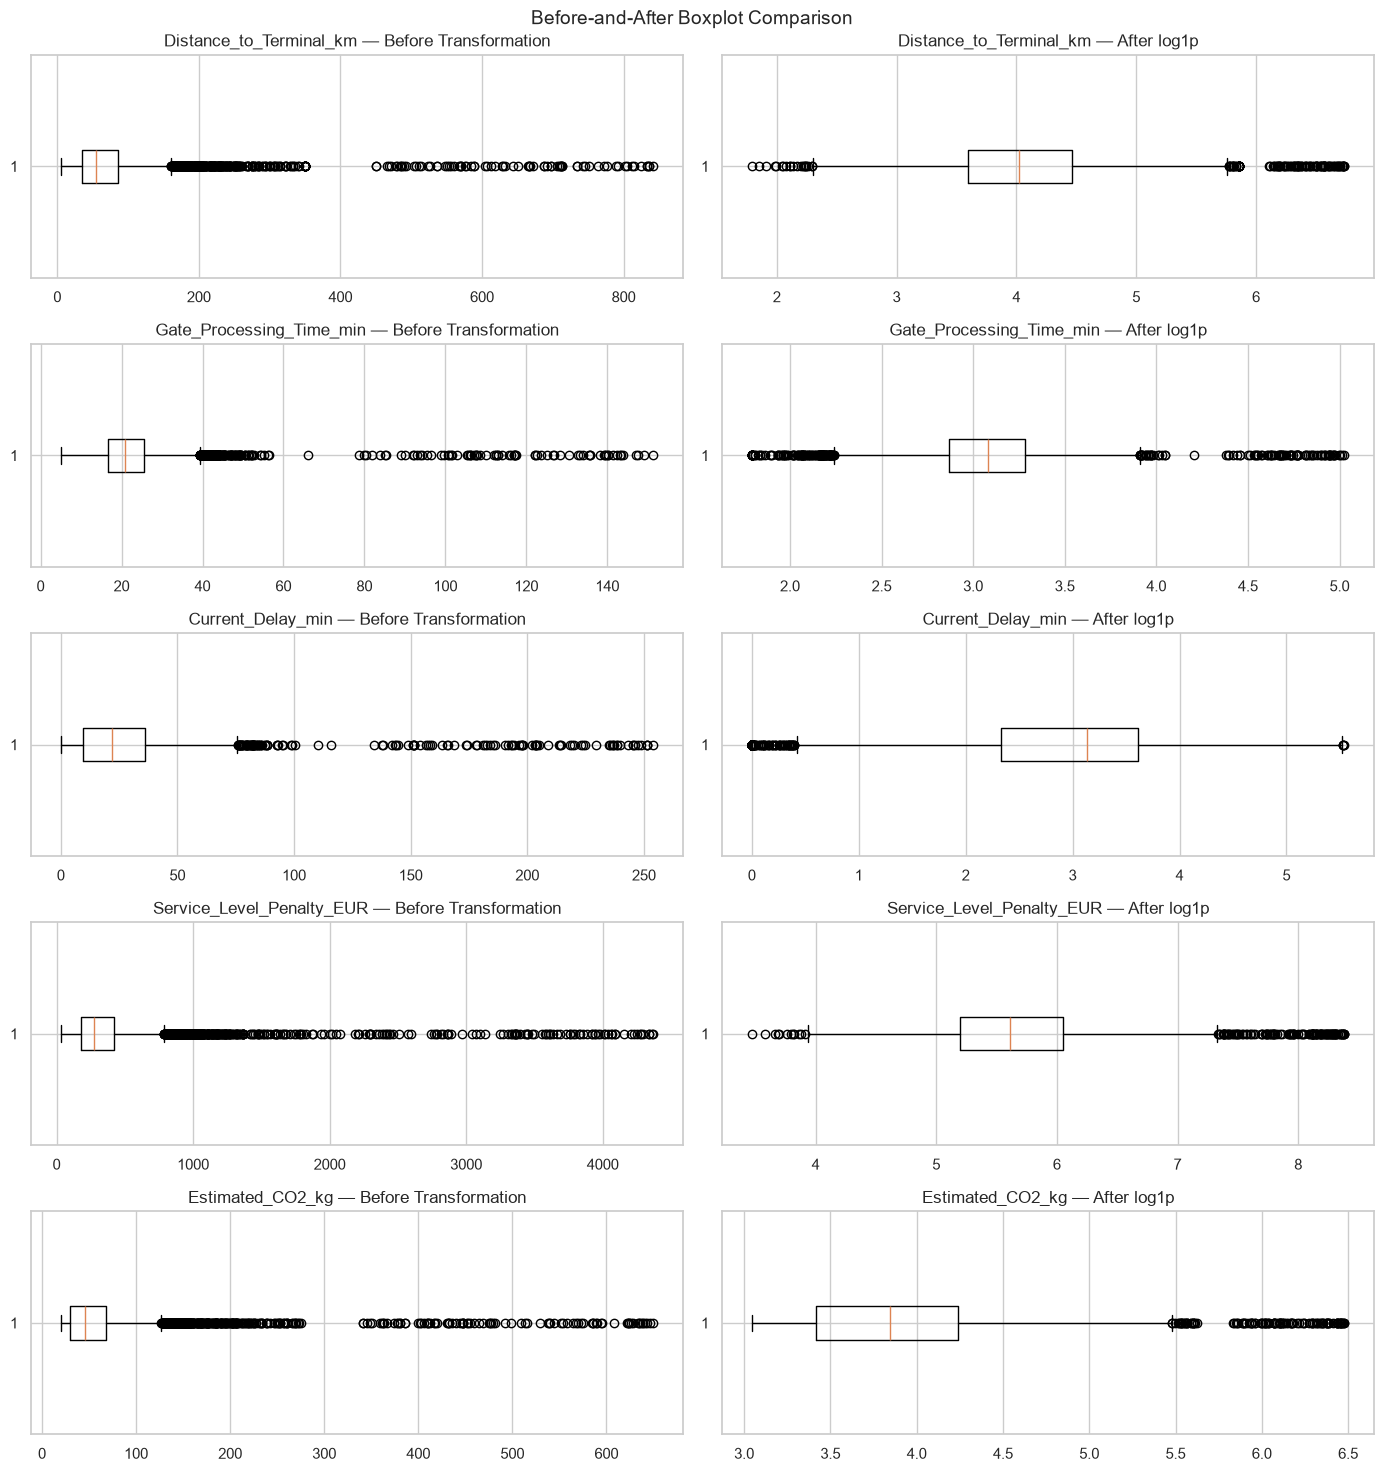

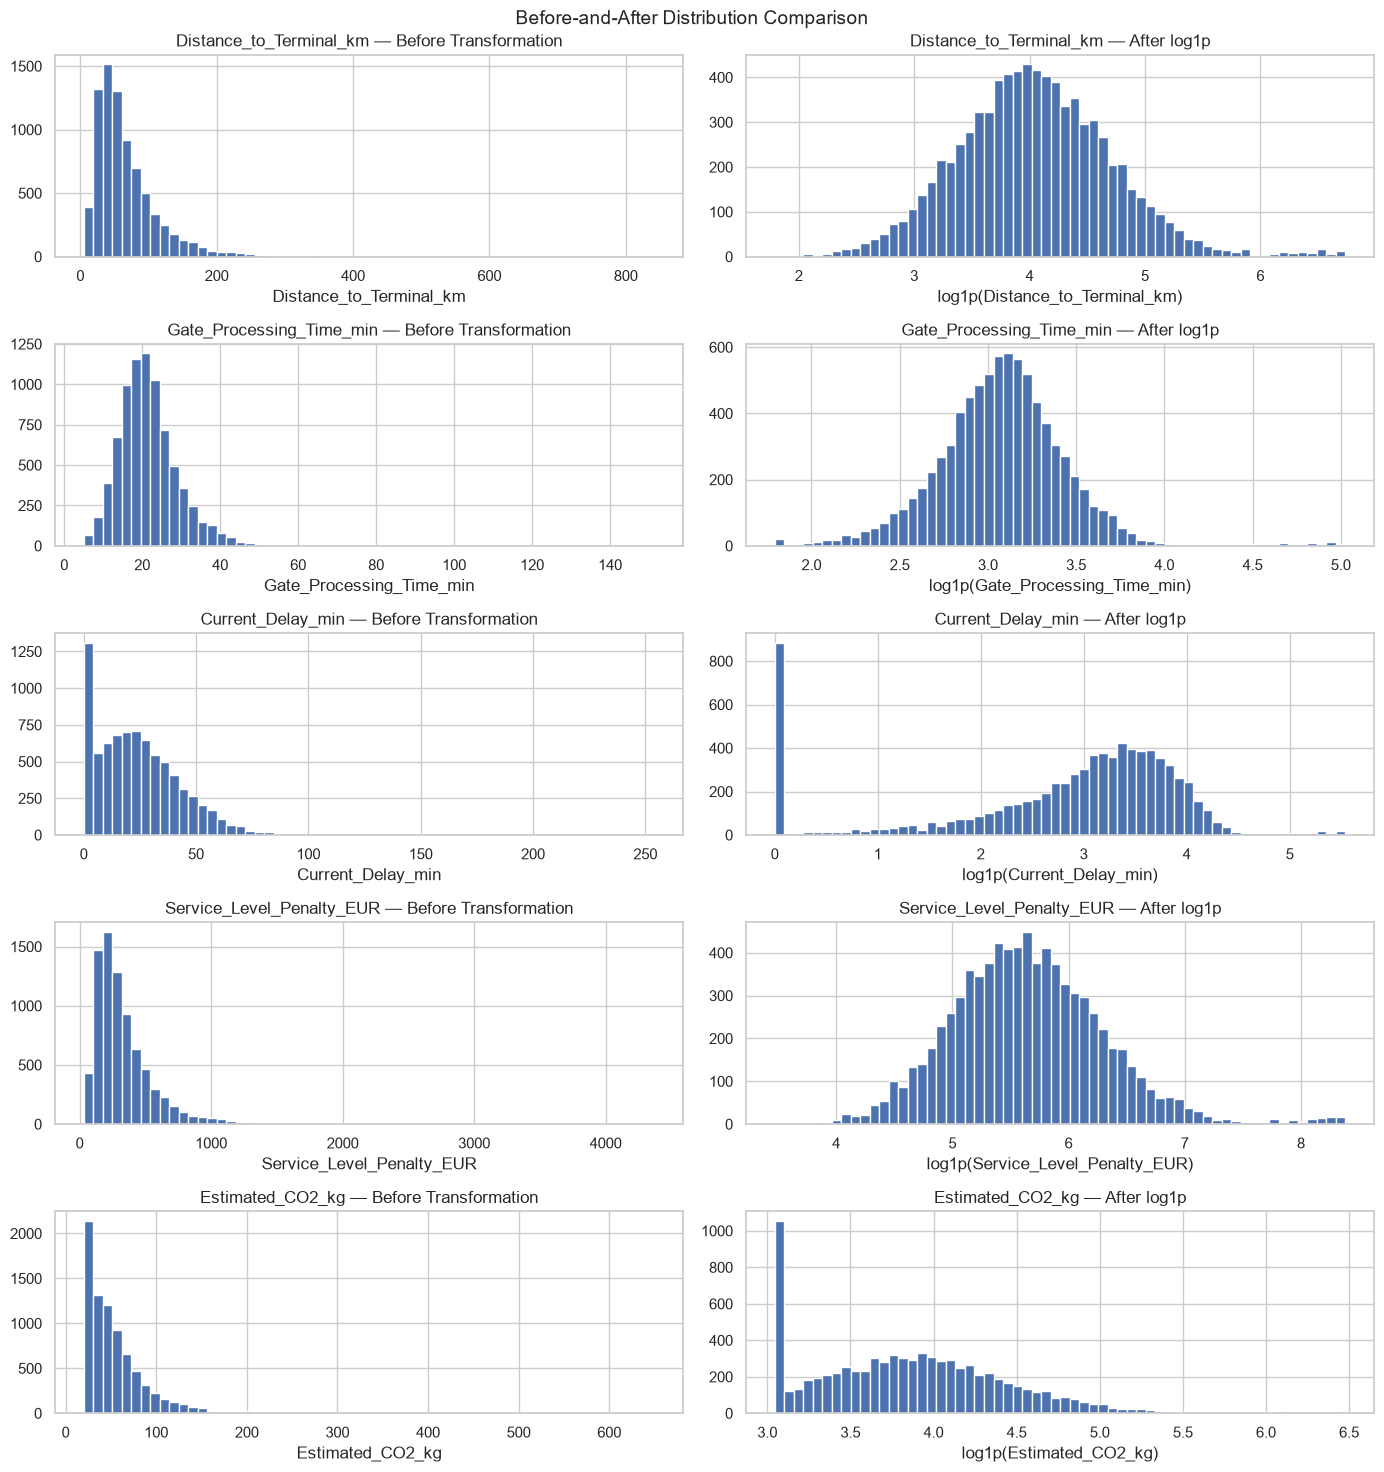

In [65]:
import matplotlib.pyplot as plt

# ============================================================
# 1. Boxplots: before vs. after
# ============================================================
fig, axes = plt.subplots(
    len(heavy), 2,
    figsize=(14, 3 * len(heavy))
)

for i, col in enumerate(heavy):

    # Before transformation
    axes[i, 0].boxplot(
        X_train_before_log1p[col],
        vert=False
    )
    axes[i, 0].set_title(f"{col} — Before Transformation")

    # After transformation
    axes[i, 1].boxplot(
        X_train[col],
        vert=False
    )
    axes[i, 1].set_title(f"{col} — After log1p")

plt.suptitle(
    "Before-and-After Boxplot Comparison",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ============================================================
# 2. Histograms: before vs. after
# ============================================================
fig, axes = plt.subplots(
    len(heavy), 2,
    figsize=(14, 3 * len(heavy))
)

for i, col in enumerate(heavy):

    # Before transformation
    axes[i, 0].hist(
        X_train_before_log1p[col],
        bins=60
    )
    axes[i, 0].set_title(f"{col} — Before Transformation")
    axes[i, 0].set_xlabel(col)

    # After transformation
    axes[i, 1].hist(
        X_train[col],
        bins=60
    )
    axes[i, 1].set_title(f"{col} — After log1p")
    axes[i, 1].set_xlabel(f"log1p({col})")

plt.suptitle(
    "Before-and-After Distribution Comparison",
    fontsize=14
)

plt.tight_layout()
plt.show()

#### Comparison of visualization and explanation Before and After handling of Outliers

In order to assess the impact of the chosen outlier-handling method, the following boxplots and distribution barplots were created for five of the most heavily right-skewed numeric features before and after a log1p transformation was performed.

- `Distance_to_Terminal_km`
- `Gate_Processing_Time_min`
- `Current_Delay_min`
- `Service_Level_Penalty_EUR`
- `Estimated_CO2_kg`

1. Boxplot Comparison

The boxplots before transformation display a high degree of right skewness, with many observations well past the upper whiskers. This is most evident for the features `Distance_to_Terminal_km`, `Gate_Processing_Time_min`, `Current_Delay_min`, `Service_Level_Penalty_EUR`, and `Estimated_CO2_kg`.

After the log1p transformation, the distributions become considerably more compact. The distance between the central observations and the extreme upper values is reduced, and the interquartile ranges become more representative of the overall distributions.

Nevertheless, it is interesting to note that some of the points do appear beyond the boxplot whiskers. This is as expected, as the transformation does not ensure no observation appears as an outlier, nor does it ensure all values are contained within the quartiles. It merely scales the points and the influence of the larger values is much reduced.

2. Distribution Comparison

This makes the histograms provide further evidence of the transformation's effect:

- `Distance_to_Terminal_km`: The original distribution exhibits a pronounced right tail. After transformation, it becomes substantially more symmetric and approximately bell-shaped.
- `Gate_Processing_Time_min`: The original right-skewed distribution becomes considerably more balanced, with most observations concentrated around the centre.
- `Current_Delay_min`: The transformation reduces the long right tail and makes the positive delay values more compact. Nonetheless, there is still a prominent concentration at zero representing cases with no current delay, giving a spike at zero on the transformed distribution.
- `Service_Level_Penalty_EUR`: The original distribution contains a long upper tail with very large penalty values. The distribution appears to be considerably more symmetric after transformation while retaining its extreme observations.
- `Estimated_CO2_kg`: The transformation considerably compresses the upper tail and reduces the original right-skewness. Some asymmetry and extreme upper values remain, but their scale is substantially reduced.

3. Effects of Outlier Handling

Overall, the comparison demonstrates several effects of applying the logarithmic transformation:

1. Reduced skewness: The pronounced right-skewness of the selected features is substantially reduced, resulting in more balanced distributions.
2. Compressed extreme values: Large observations are brought closer to the central part of their respective distributions, reducing the dominance of extreme values.
3. Improved distribution symmetry: Most transformed features become considerably more symmetric, although this does not imply that they follow a perfectly normal distribution.
4. No rows were removed, and no values were capped or replaced. All observations remain available for subsequent modelling.
5. Extreme logistics observations remain in the dataset, preserving potentially important information about long distances, substantial delays, high service-level penalties, and elevated emissions.

Conclusion

The log1p transformation effectively addresses the pronounced right-skewness of the five heavily right-skewed numerical features while preserving the original observations. Whilst a few of the extremes are still visible in the transformed boxplots, they are less extreme and its effect on the distributions is greatly reduced.

Therefore, the adopted approach provides a reasonable balance between reducing the impact of extreme values and retaining potentially meaningful operational information. It also avoids unnecessary observation removal or Winsorization, which could otherwise suppress genuine logistics scenarios.

# Part 5: Encoding categorical (nominal and ordinal) data


#### Cell 1: Displaying the categorical (nominal and ordinal) features

In [66]:
import pandas as pd

nominal_cols = [
    "Day_of_Week",
    "Shift",
    "Terminal_ID",
    "Corridor_ID",
    "Transport_Object_Type",
    "Vehicle_Type",
    "Customs_Status"
]

binary_cols = [
    "Trailer_Ready",
    "Alternative_Slot_Available",
    "Alternative_Terminal_Available",
    "Alternative_Route_Available",
    "Driver_Change_Available"
]

ordinal_cols = [
    "Cargo_Priority",
    "Terminal_Incident_Severity",
    "Road_Incident_Severity",
    "Vehicle_Technical_Status"
]

categorical_cols = nominal_cols + binary_cols + ordinal_cols

categorical_summary = pd.DataFrame({
    "Feature": categorical_cols,
    "Category Type": (
        ["Nominal"] * len(nominal_cols)
        + ["Binary Nominal"] * len(binary_cols)
        + ["Ordinal"] * len(ordinal_cols)
    ),
    "Data Type": [X_train[col].dtype for col in categorical_cols],
    "Unique Values": [X_train[col].nunique() for col in categorical_cols],
    "Observed Categories": [
        sorted(X_train[col].dropna().unique().tolist(), key=str)
        for col in categorical_cols
    ]
})

display(categorical_summary)

print(f"Total categorical features: {len(categorical_cols)}")

,Feature,Category Type,Data Type,Unique Values,Observed Categories
0,Day_of_Week,Nominal,category,7,"[Friday, Monday, Saturday, Sunday, Thursday, T..."
1,Shift,Nominal,category,3,"[Day, Evening, Night]"
2,Terminal_ID,Nominal,category,4,"[T1, T2, T3, T4]"
3,Corridor_ID,Nominal,category,5,"[C1, C2, C3, C4, C5]"
4,Transport_Object_Type,Nominal,string[python],3,"[Container, Swap_Body, Trailer]"
5,Vehicle_Type,Nominal,category,3,"[Rigid_Truck, Swap_Body_Truck, Tractor_Unit]"
6,Customs_Status,Nominal,string[python],3,"[Cleared, Hold, Pending]"
7,Trailer_Ready,Binary Nominal,boolean,2,"[False, True]"
8,Alternative_Slot_Available,Binary Nominal,boolean,2,"[False, True]"
9,Alternative_Terminal_Available,Binary Nominal,boolean,2,"[False, True]"


Total categorical features: 16


#### Cell 2: Encode the categorical (nominal + ordinal) features

In [67]:
import pandas as pd
from sklearn.preprocessing import LabelBinarizer, OrdinalEncoder

# --------------------------------------------------
# 1. Define categorical feature groups
# --------------------------------------------------

nominal_cols = [
    "Day_of_Week",
    "Shift",
    "Terminal_ID",
    "Corridor_ID",
    "Transport_Object_Type",
    "Vehicle_Type",
    "Customs_Status"
]

binary_nominal_cols = [
    "Trailer_Ready",
    "Alternative_Slot_Available",
    "Alternative_Terminal_Available",
    "Alternative_Route_Available",
    "Driver_Change_Available"
]

ordinal_cols = [
    "Vehicle_Technical_Status"
]

# Store fitted encoders
label_binarizers = {}


# --------------------------------------------------
# 2. One-hot encoding: multicategory nominal features
# --------------------------------------------------

for col in nominal_cols:

    encoder = LabelBinarizer()

    train_encoded = encoder.fit_transform(X_train[col])
    test_encoded = encoder.transform(X_test[col])

    encoded_cols = [
        f"{col}_{category}" for category in encoder.classes_
    ]

    train_df = pd.DataFrame(
        train_encoded,
        columns=encoded_cols,
        index=X_train.index
    )

    test_df = pd.DataFrame(
        test_encoded,
        columns=encoded_cols,
        index=X_test.index
    )

    X_train = pd.concat(
        [X_train.drop(columns=col), train_df], axis=1
    )

    X_test = pd.concat(
        [X_test.drop(columns=col), test_df], axis=1
    )

    label_binarizers[col] = encoder


# --------------------------------------------------
# 3. Ordinal encoding: binary nominal features
# --------------------------------------------------

binary_encoder = OrdinalEncoder(
    categories=[[False, True]] * len(binary_nominal_cols)
)

X_train[binary_nominal_cols] = binary_encoder.fit_transform(
    X_train[binary_nominal_cols]
)

X_test[binary_nominal_cols] = binary_encoder.transform(
    X_test[binary_nominal_cols]
)


# --------------------------------------------------
# 4. Ordinal encoding: textual ordinal feature
# --------------------------------------------------

ordinal_encoder = OrdinalEncoder(
    categories=[["OK", "Warning", "Critical"]]
)

for col in ordinal_cols:

    X_train[[col]] = ordinal_encoder.fit_transform(X_train[[col]])
    X_test[[col]] = ordinal_encoder.transform(X_test[[col]])


# --------------------------------------------------
# 5. Existing numerical ordinal features
# --------------------------------------------------

# Cargo_Priority
# Terminal_Incident_Severity
# Road_Incident_Severity

# These remain unchanged because their numerical
# values already represent their ordinal order.


# --------------------------------------------------
# 6. Validation
# --------------------------------------------------

# Verify feature consistency
assert X_train.columns.equals(X_test.columns)

# Verify row counts
assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)

# Verify no missing values remain
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

# Verify target and feature index alignment
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("All encoding validations passed.")

All encoding validations passed.


#### Cell 3: Encode the Target 'Recommended_Dispatch_Action' Labels using Label encoding

In [68]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()

y_train = pd.Series(
    target_encoder.fit_transform(y_train),
    index=y_train.index,
    name="Recommended_Dispatch_Action"
)

y_test = pd.Series(
    target_encoder.transform(y_test),
    index=y_test.index,
    name="Recommended_Dispatch_Action"
)

# Display the mapping
target_mapping = pd.DataFrame({
    "Original Class": target_encoder.classes_,
    "Encoded Label": range(len(target_encoder.classes_))
})

display(target_mapping)

print("Target encoding completed successfully.")

,Original Class,Encoded Label
0,PRIORITY_RECOVERY,0
1,PROCEED_AS_PLANNED,1
2,REASSIGN_VEHICLE,2
3,REROUTE,3
4,RESCHEDULE_SLOT,4
5,WAIT_AND_MONITOR,5


Target encoding completed successfully.


#### Cell 4: Print the categorical features summary after encoding

In [70]:
categorical_cols = (
    nominal_cols + binary_nominal_cols
    + ["Cargo_Priority", "Terminal_Incident_Severity",
       "Road_Incident_Severity", "Vehicle_Technical_Status"]
)

categorical_summary_after = []

for col in categorical_cols:

    # One-hot encoded nominal features
    if col in nominal_cols:
        encoder = label_binarizers[col]
        values = sorted(X_train[
            [f"{col}_{category}" for category in encoder.classes_]
        ].drop_duplicates().apply(
            lambda row: tuple(row), axis=1
        ).unique().tolist())

        data_type = "One-hot encoded"
        unique_values = len(values)
        observed = values

    # Binary nominal and ordinal features
    else:
        observed = sorted(X_train[col].dropna().unique().tolist())
        data_type = str(X_train[col].dtype)
        unique_values = X_train[col].nunique()

    categorical_summary_after.append({
        "Feature": col,
        "Category Type": (
            "Nominal" if col in nominal_cols
            else "Binary Nominal" if col in binary_nominal_cols
            else "Ordinal"
        ),
        "Data Type": data_type,
        "Unique Values": unique_values,
        "Observed Categories": observed
    })

categorical_summary_after = pd.DataFrame(categorical_summary_after)

display(categorical_summary_after)

,Feature,Category Type,Data Type,Unique Values,Observed Categories
0,Day_of_Week,Nominal,One-hot encoded,7,"[(0, 0, 0, 0, 0, 0, 1), (0, 0, 0, 0, 0, 1, 0),..."
1,Shift,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
2,Terminal_ID,Nominal,One-hot encoded,4,"[(0, 0, 0, 1), (0, 0, 1, 0), (0, 1, 0, 0), (1,..."
3,Corridor_ID,Nominal,One-hot encoded,5,"[(0, 0, 0, 0, 1), (0, 0, 0, 1, 0), (0, 0, 1, 0..."
4,Transport_Object_Type,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
5,Vehicle_Type,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
6,Customs_Status,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
7,Trailer_Ready,Binary Nominal,float64,2,"[0.0, 1.0]"
8,Alternative_Slot_Available,Binary Nominal,float64,2,"[0.0, 1.0]"
9,Alternative_Terminal_Available,Binary Nominal,float64,2,"[0.0, 1.0]"


the Ordinal Encoder from scikit-learn return floating points arrays, therefore it will be more suitable
to convert the data type to int

In [71]:
# Convert binary nominal variables to integers
X_train[binary_nominal_cols] = X_train[binary_nominal_cols].astype("int8")
X_test[binary_nominal_cols] = X_test[binary_nominal_cols].astype("int8")

# Convert encoded ordinal technical status to integers
X_train["Vehicle_Technical_Status"] = (
    X_train["Vehicle_Technical_Status"].astype("int8")
)

X_test["Vehicle_Technical_Status"] = (
    X_test["Vehicle_Technical_Status"].astype("int8")
)

print("Binary nominal and ordinal variables converted to integer types.")

Binary nominal and ordinal variables converted to integer types.


rerun the categorical feature summary cell after converting the ordinally encoded
binary nominal and 'Vehicle_Technical_Status' columns data types from float64 (induced by the OrdinalEncoder() from scikit-learn) to int

In [72]:
categorical_cols = (
    nominal_cols + binary_nominal_cols
    + ["Cargo_Priority", "Terminal_Incident_Severity",
       "Road_Incident_Severity", "Vehicle_Technical_Status"]
)

categorical_summary_after = []

for col in categorical_cols:

    # One-hot encoded nominal features
    if col in nominal_cols:
        encoder = label_binarizers[col]
        values = sorted(X_train[
            [f"{col}_{category}" for category in encoder.classes_]
        ].drop_duplicates().apply(
            lambda row: tuple(row), axis=1
        ).unique().tolist())

        data_type = "One-hot encoded"
        unique_values = len(values)
        observed = values

    # Binary nominal and ordinal features
    else:
        observed = sorted(X_train[col].dropna().unique().tolist())
        data_type = str(X_train[col].dtype)
        unique_values = X_train[col].nunique()

    categorical_summary_after.append({
        "Feature": col,
        "Category Type": (
            "Nominal" if col in nominal_cols
            else "Binary Nominal" if col in binary_nominal_cols
            else "Ordinal"
        ),
        "Data Type": data_type,
        "Unique Values": unique_values,
        "Observed Categories": observed
    })

categorical_summary_after = pd.DataFrame(categorical_summary_after)

display(categorical_summary_after)

,Feature,Category Type,Data Type,Unique Values,Observed Categories
0,Day_of_Week,Nominal,One-hot encoded,7,"[(0, 0, 0, 0, 0, 0, 1), (0, 0, 0, 0, 0, 1, 0),..."
1,Shift,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
2,Terminal_ID,Nominal,One-hot encoded,4,"[(0, 0, 0, 1), (0, 0, 1, 0), (0, 1, 0, 0), (1,..."
3,Corridor_ID,Nominal,One-hot encoded,5,"[(0, 0, 0, 0, 1), (0, 0, 0, 1, 0), (0, 0, 1, 0..."
4,Transport_Object_Type,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
5,Vehicle_Type,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
6,Customs_Status,Nominal,One-hot encoded,3,"[(0, 0, 1), (0, 1, 0), (1, 0, 0)]"
7,Trailer_Ready,Binary Nominal,int8,2,"[0, 1]"
8,Alternative_Slot_Available,Binary Nominal,int8,2,"[0, 1]"
9,Alternative_Terminal_Available,Binary Nominal,int8,2,"[0, 1]"


#### Categorical Encoding Strategy and Rationale

The encoding techniques can be summarized according to the types of categorical feature: nominal, binary nominal and ordinal. The main goal was to encode the categorical features to numerical one and preserve the semantics and structure of the related values.

1. Nominal Features - One-Hot Encoding

The following features were One-Hot Encoded using Label Binarizer:

- Day_of_Week
- Shift
- Terminal_ID
- Corridor_ID
- Transport_Object_Type
- Vehicle_Type
- Customs_Status

This indicates that these variables are nominal categories without any ordinal relationship. One-Hot encoding creates dummy variables to make dummy variables for each of these categorical variables, hence we can eliminate the effect of an ordinal relationship between the dummy variables and the model not to interpret their values as numerical sequence that means something.

2. Binary Nominal Features - Ordinal Encoding

Boolean features are encoded with `OrdinalEncoder` as follows:

- `Trailer_Ready`
- `Alternative_Slot_Available`
- `Alternative_Terminal_Available`
- `Alternative_Route_Available`
- `Driver_Change_Available`

All these features are binary with only two states available, False and True. These features were encoded to 0 and 1 respectively. Although these variables are not really ordinal, the Ordinal encoding is valid here because it just provides the relevant distinction between the two available states. This method will also prevent an additional column from being added for each boolean feature which could be undesirable.

3. Ordinal Features - Ordinal Encoding or Preservation of Existing Order

Ordinal features were treated as follows when their categories were preexpressed numerically:

- The feature 'Vehicle_Technical_Status' was ordinal-encoded using the Ordinal Encoder method: OK(0), Warning(1), Critical(2). The encoding keeps the increasing severity of the technical state of the vehicle.
- The values for 'Cargo_Priority', 'Terminal_Incident_Severity' and 'Road_Incident_Severity' were kept as they are, as the individual values already reflect the ordinal relationships of the data. Another step of encoding would be unnecessary and would not provide any extra information.

4. Target Variable - Label Encoding

'Recommended_Dispatch_Action', the variable being predicted, was a nominal class label with six possible values. It was encoded using Label Encoder, which creates an integer label for each class.

In this case, Label Encoding would be an appropriate technique as the class labels aren’t indicative of ordered quality. The integer values provided by Label Encoding can be used as category identifiers.

5. Leakage Prevention

The encoders were all fit on only the training data, and then applied on the test data with the same  fitted mappings, to guarantee the same category representations and not leak information from the test set.

Briefly, the proposed encoding approach maintains the separation between nominal categories, the two states of binary variables and the order of the ordinal features, and at the same time gives numeric inputs for the subsequent machine-learning models.

#### Cell 5: Hour (an engineered cyclic feature) --> requires cyclic encoding

In [75]:
import numpy as np

# Apply cyclic encoding to Hour
for df in [X_train, X_test]:
    df["Hour_sin"] = np.sin(2 * np.pi * df["Hour"] / 24)
    df["Hour_cos"] = np.cos(2 * np.pi * df["Hour"] / 24)

    # Remove original Hour column
    df.drop(columns=["Hour"], inplace=True)

print("Cyclic encoding completed successfully.")

print("New features: Hour_sin, Hour_cos")
print("Original Hour column removed.")

assert "Hour" not in X_train.columns
assert "Hour" not in X_test.columns
assert X_train.columns.equals(X_test.columns)

Cyclic encoding completed successfully.
New features: Hour_sin, Hour_cos
Original Hour column removed.


The Hour feature was cyclically encoded with the use of sine and cosine transformations to maintain the circular relationships between hours ( for example 23:00 and 00:00 as they are close to each other). The original column was replaced by `Hour_sin` and `Hour_cos` to provide a more meaningful representation of time.

# Part 6: Feature scaling

#### Cell 1: Display the continuous numerical features (that will be scaled)

In [78]:
# Identify continuous numerical features
continuous_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in (
        binary_nominal_cols
        + [
            "Cargo_Priority",
            "Terminal_Incident_Severity",
            "Road_Incident_Severity",
            "Vehicle_Technical_Status",
            "Hour_sin",
            "Hour_cos"
        ]
        + [
            encoded_col
            for encoder_col, encoder in label_binarizers.items()
            for encoded_col in [
                f"{encoder_col}_{category}"
                for category in encoder.classes_
            ]
        ]
    )
]

# Display continuous numerical features
continuous_summary = pd.DataFrame({
    "Feature": continuous_cols,
    "Data Type": X_train[continuous_cols].dtypes.astype(str).values,
    "Unique Values": X_train[continuous_cols].nunique().values
})

display(continuous_summary)

print(f"Total continuous numerical features to be scaled: {len(continuous_cols)}")

,Feature,Data Type,Unique Values
0,Distance_to_Terminal_km,float64,5881
1,Weather_Severity_Index,float64,3633
2,Terminal_Congestion_Index,float64,4513
3,Road_Congestion_Index,float64,4818
4,Yard_Occupancy_pct,float64,3822
5,Queue_Length_vehicles,Int64,29
6,Gate_Processing_Time_min,float64,2977
7,Expected_Disruption_Duration_min,float64,4272
8,Current_Delay_min,float64,4383
9,ETA_Uncertainty_min,float64,2947


Total continuous numerical features to be scaled: 22


#### Cell 2: Apply RobustScaler for the selected 22 numerical features

In [79]:

from sklearn.preprocessing import RobustScaler

# The 22 numerical features selected for scaling
scaler = RobustScaler()

# Preserve original values for before-and-after comparison
X_train_before_scaling = X_train[continuous_cols].copy(deep=True)
X_test_before_scaling = X_test[continuous_cols].copy(deep=True)

# Fit on training data and transform both datasets
X_train.loc[:, continuous_cols] = scaler.fit_transform(
    X_train[continuous_cols]
)

X_test.loc[:, continuous_cols] = scaler.transform(
    X_test[continuous_cols]
)

print("Robust scaling completed successfully.")
print(f"Number of scaled features: {len(continuous_cols)}")
print("Scaler fitted on training data and applied to test data.")

Robust scaling completed successfully.
Number of scaled features: 22
Scaler fitted on training data and applied to test data.


C:\Users\user\AppData\Local\Temp\ipykernel_28968\4086760541.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.4 -0.4  0.4 ...  0.8 -0.6  0.4]' has dtype incompatible with Int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, continuous_cols] = scaler.fit_transform(
C:\Users\user\AppData\Local\Temp\ipykernel_28968\4086760541.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-1.5  1.5 -1.5 ...  0.5  1.  -0.5]' has dtype incompatible with Int64, please explicitly cast to a compatible dtype first.
  X_train.loc[:, continuous_cols] = scaler.fit_transform(
C:\Users\user\AppData\Local\Temp\ipykernel_28968\4086760541.py:11: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.   0.5  0.  ...  0.   0.5 -0.5]' has dtype incompatible with Int64, please ex

#### Cell 3: Confirm the scaling results and check the median and IQR for the scaled features

In [80]:
# Confirm that the selected columns were scaled
assert len(continuous_cols) == 22

# Confirm train/test feature consistency
assert X_train.columns.equals(X_test.columns)

# Confirm no missing values were introduced
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

# Check the median and IQR of the scaled training features
scaling_check = pd.DataFrame({
    "Median": X_train[continuous_cols].median(),
    "IQR": (
        X_train[continuous_cols].quantile(0.75)
        - X_train[continuous_cols].quantile(0.25)
    )
}).round(3)

display(scaling_check)

print("Scaling validation passed.")


,Median,IQR
Distance_to_Terminal_km,0.0,1.0
Weather_Severity_Index,0.0,1.0
Terminal_Congestion_Index,0.0,1.0
Road_Congestion_Index,0.0,1.0
Yard_Occupancy_pct,0.0,1.0
Queue_Length_vehicles,0.0,1.0
Gate_Processing_Time_min,0.0,1.0
Expected_Disruption_Duration_min,0.0,1.0
Current_Delay_min,0.0,1.0
ETA_Uncertainty_min,0.0,1.0


Scaling validation passed.


### Feature Scaling Strategy and Justification

The choice of the Robust Scaler for scaling the numerical measurement features was based on the distributions uncovered in the exploratory data analysis, which showed that many numerical features contained outliers, and since we want to retain these outliers that can represent meaningful operational disruption scenarios but we don't want them to have strong infulence, RobustScaler is the best suitable approach.

Robust Scaler was favored over alternative scaling methods for several reasons:

- The Standard Scaler uses the mean and standard deviation that are affected by outliers. As the data contains potential outliers, the mean and standard deviation are affected by these extreme values.
- The Min Max Scaler performs a scale to a fixed range [ 0, 1] minmax scaling can be also sensitive to outliers as it will compress the majority of data points into a narrow range.
- Max Abs Scaler scales each feature by its maximum absolute value. Like Min Max Scaler, it can be strongly influenced by extreme observations and does not center the distributions.
- RobustScaler uses the median for centering and the interquartile range (IQR) for scaling. Since these statistics are less sensitive to extreme observations, this method is more appropriate for the distributions observed in our dataset, as we want to preserve the outliers that represent important operational disruption scenarios like severe traffic congestion, severe weather disruptions, significant transport delays and high financial exposure (represented by the outliers of column 'Severe_Level_Penalty_EUR'), but also we don't want these outliers to have a strong influence; we also want to prevent these extreme observations from disproportionately influencing the scaling parameters. RobustScaler addresses this by centering each feature around its median (resulting in a median of approximately zero) and scaling it by its IQR (resulting in an IQR of approximately one). Therefore, it is the most suitable scaling approach for our dataset.

Features to Scale

Scaling was restricted to the 22 selected numerical measurement features. The remaining features were deliberately excluded because their existing numerical representations already carry meaningful information:

- Nominal: One-hot encoded Nominal features are one-hot encoded, where the feature is represented by either 0 or 1 as a binary indicator of class. These features shouldn't be scaled, and scaling could result in binary values being altered.
- Binary nominal features were encoded as 0 and 1 for the two classes (True and False), keeping their binary representation is therefore implemented as scaling also will alter their binary representation.
- Ordinal features were encoded according to their predefined category order, resulting in bounded integer representations such as 0-1-2 and 0-1-2-3. These values were retained to preserve the intended ordering. For example, Vehicle_Technical_Status was encoded as follows:

| Category | Encoding |
|---|---:|
| OK | 0 |
| Warning | 1 |
| Critical | 2 |

This encoding preserves the progression from normal to increasingly severe technical conditions. It does, however,  it also imply equal spacing of the levels - an assumption within the ordinal approach (i.e. OrdinalEncoder) used.
- The original Hour variable was replaced by Hour_sin and Hour_cos to preserve the cyclical relationship between hours of the day; for example, 23:00 and 00:00 are temporally adjacent, despite their numerical values being far apart in the original representation. The sine and cosine transformations capture this relationship, producing values naturally bounded between -1 and 1. They were left in their original trigonometric form.

Application and Prevention of Data Leakage

To prevent data leakage, the scaler was only fitted on the train set and applied to both train and test. This helps to prevent any information from the test set leaking into the scaler via the scaling parameters.

In general RobustScaler strikes a good compromise by scaling numerical measurement features to similar ranges while keeping the effect of extreme values in the data on the scaling parameters to a minimum.

#### Cell 4: paired violin plots for the 22 scaled numerical features for the before/after applying scaling

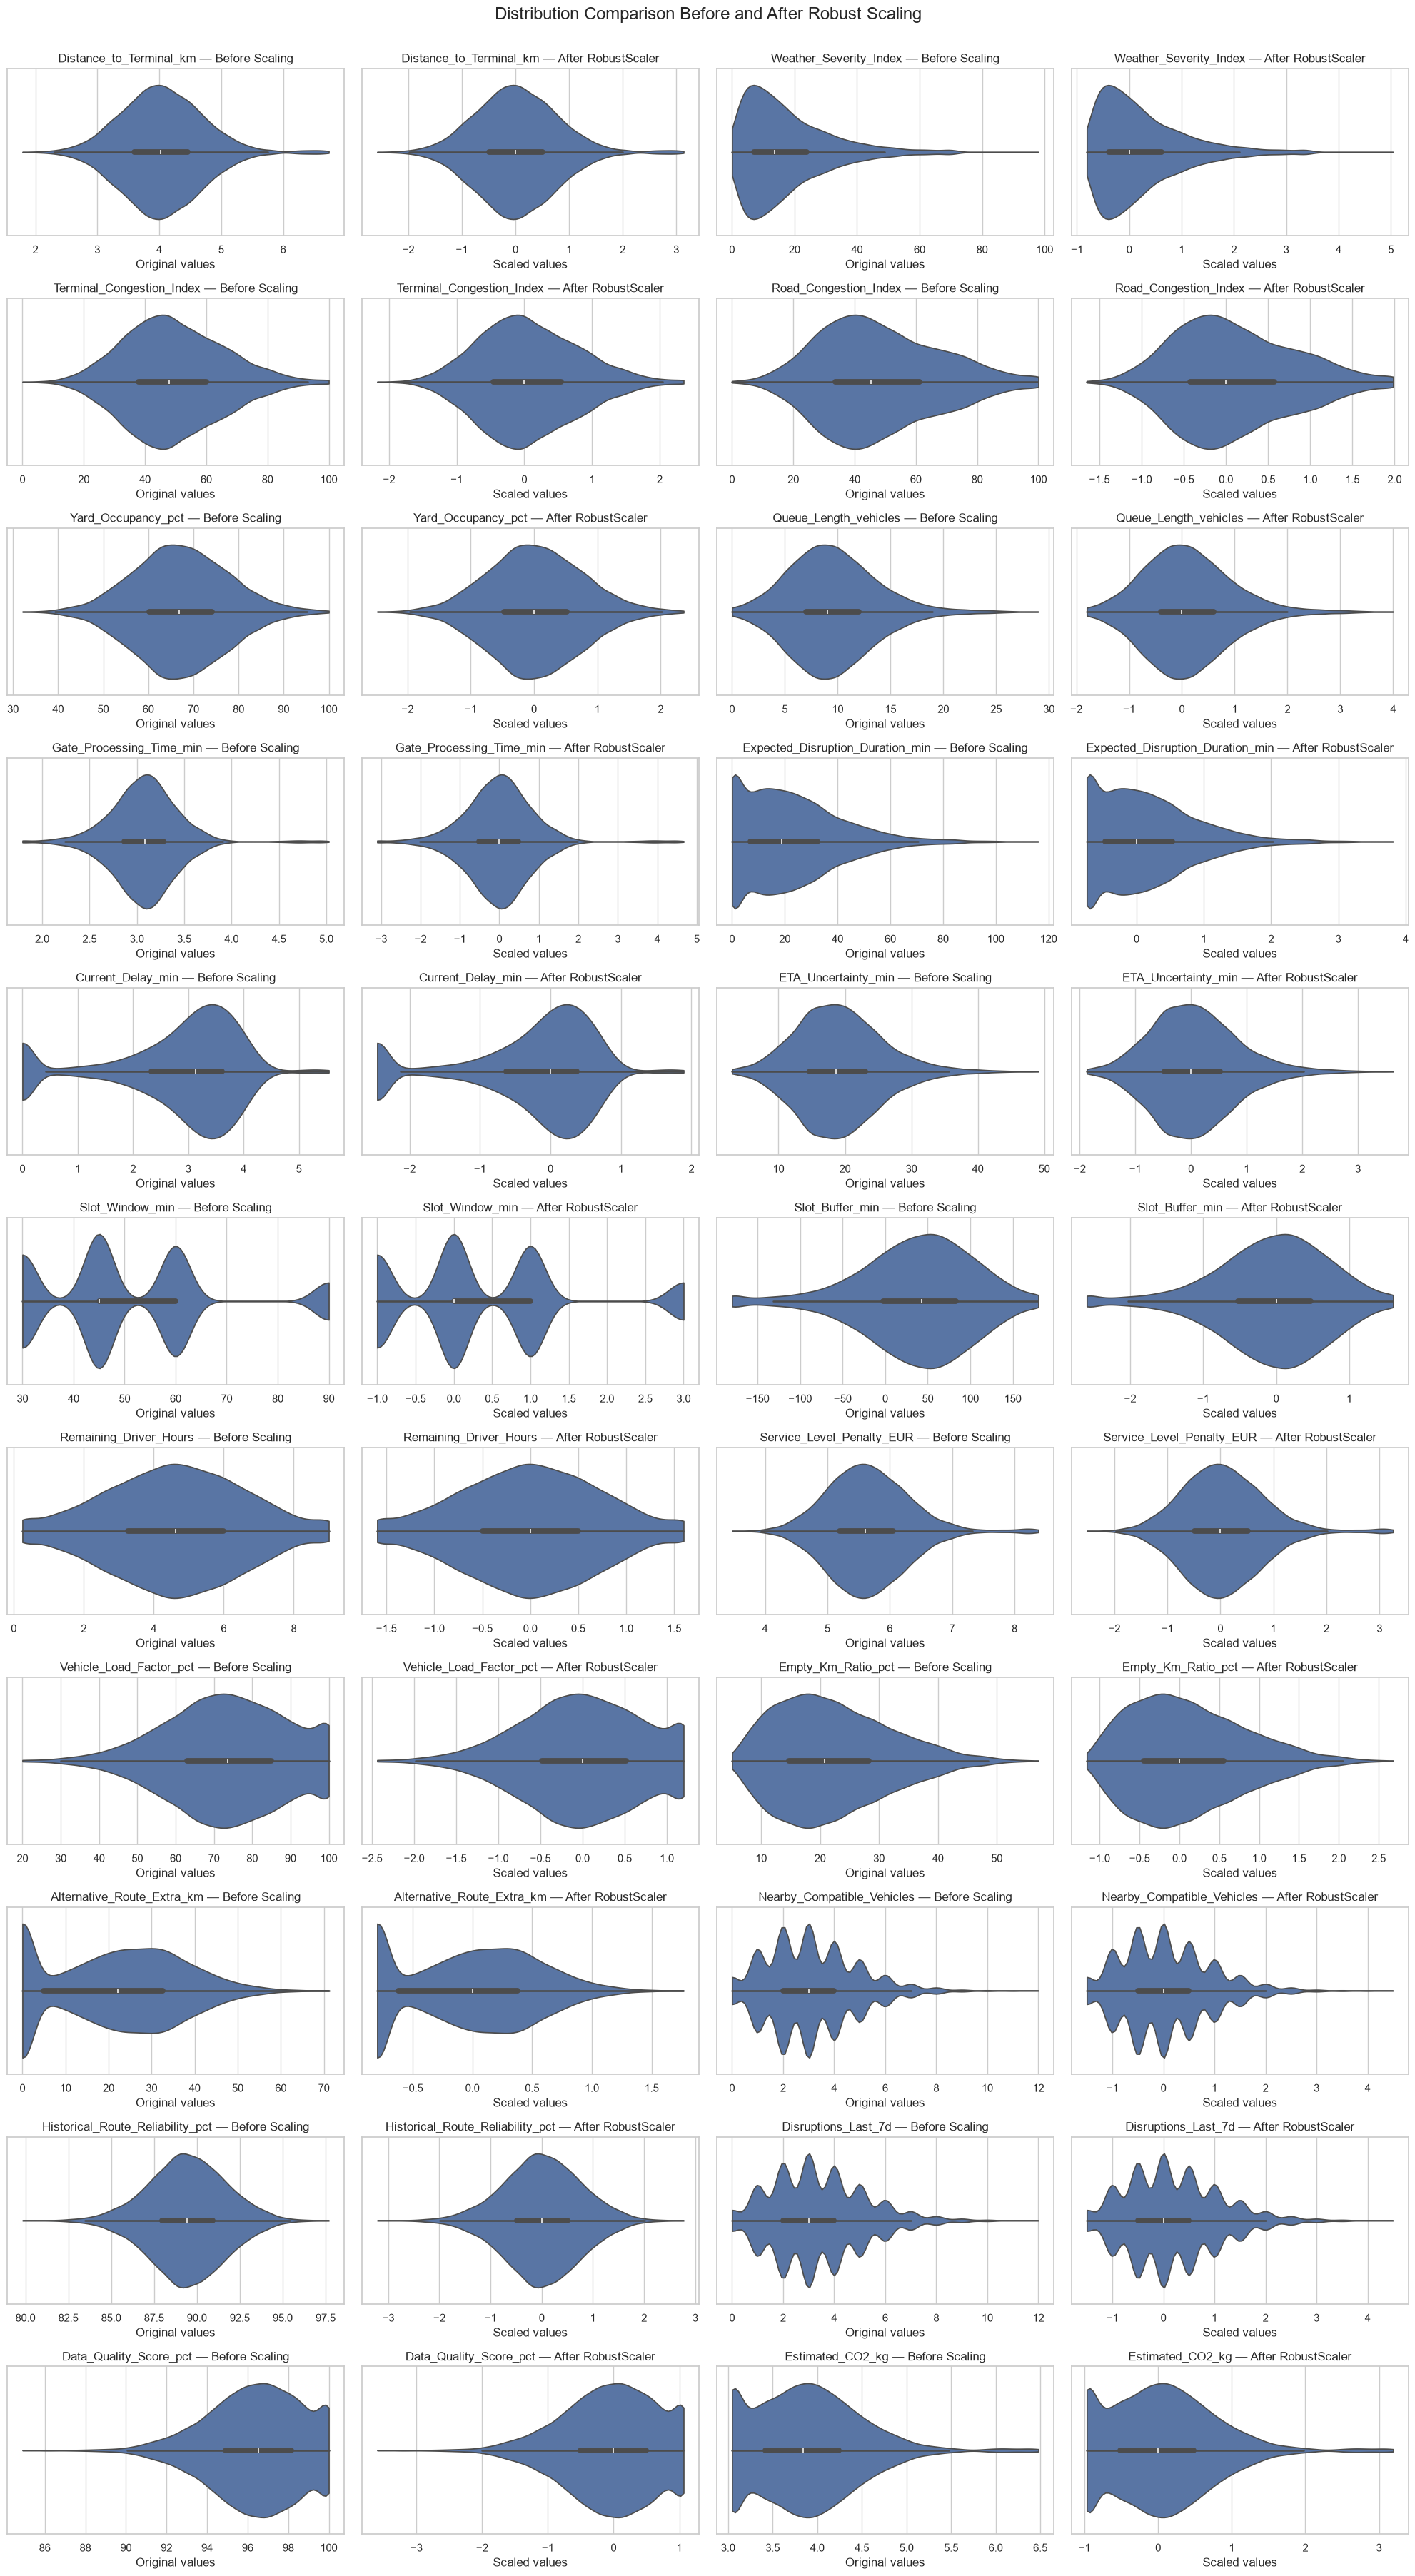

In [83]:

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    nrows=11,
    ncols=4,
    figsize=(20, 36)
)

for i, col in enumerate(continuous_cols):
    row = i // 2
    col_pos = (i % 2) * 2

    # Before scaling
    sns.violinplot(
        x=X_train_before_scaling[col],
        ax=axes[row, col_pos],
        inner="box",
        cut=0
    )
    axes[row, col_pos].set_title(f"{col} — Before Scaling")
    axes[row, col_pos].set_xlabel("Original values")

    # After scaling
    sns.violinplot(
        x=X_train[col],
        ax=axes[row, col_pos + 1],
        inner="box",
        cut=0
    )
    axes[row, col_pos + 1].set_title(f"{col} — After RobustScaler")
    axes[row, col_pos + 1].set_xlabel("Scaled values")

plt.suptitle(
    "Distribution Comparison Before and After Robust Scaling",
    fontsize=17,
    y=1.002
)

plt.tight_layout()
plt.show()


### Effects of RobustScaler

The before and after violin plots show the distributions of the 22 selected numerical features both prior to and following application of the RobustScaler. As one would expect the overall shape of the distributions is preserved, while their numerical scales and locations are adjusted.

As per the violin plots and the scaling validation results, all 22 features have a median of **0** and an interquartile range of **1** (after scaling). The features are therefore on a comparable scale with their original distributions shapes preserved.

For instance, Right skewed features stay right skewed, multi-modal features stay multi-modal and any potential extreme observations are still there as the RobustScaler doesn't remove or cap the outliers.

Although we do retain these extreme observations, their effect on the scaling parameters is minimal as the median and IQR are far less sensitive to outliers than the mean and standard deviation. That's a key reason for using the RobustScaler: you get all the observations and the extreme values have very little influence on the scaling parameters.

Furthermore it's important to bring the numerical features onto a comparable scale for the purposes of subsequent distance based algorithms as otherwise features with a large original numerical range could dominate the distance calculations. That said, the influence of individual extreme observations will still be present in those distance calculations.

RobustScaler achieves its aim in that it reduces the differences in scale of the numbers while preserving the distributional structure and all the observations. It also provides scaling parameters which are more robust to outliers, making it an appropriate choice given the outliers that were identified during the exploratory data analysis.

# Part 7: Further Preprocessing

The strategy implemented for the Further preprocessing will be explained in details in the markdown at the bottom of section 7 (Further preprocessing) along with The feature engineering process done in the below cells 

### Feature engineering

#### Cell 1: Create the two engineered features 

In [84]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# Create separate feature DataFrames.
# The original source DataFrames remain unchanged.

engineered_train = pd.DataFrame(index=X_train_before_log1p.index)
engineered_test = pd.DataFrame(index=X_test_before_log1p.index)

# 1. Alternative Route Detour Ratio
engineered_train["Alternative_Route_Detour_Ratio"] = (
    X_train_before_log1p["Alternative_Route_Extra_km"]
    / X_train_before_log1p["Distance_to_Terminal_km"]
)

engineered_test["Alternative_Route_Detour_Ratio"] = (
    X_test_before_log1p["Alternative_Route_Extra_km"]
    / X_test_before_log1p["Distance_to_Terminal_km"]
)

# 2. Slot Buffer Ratio
engineered_train["Slot_Buffer_Ratio"] = (
    X_train_before_log1p["Slot_Buffer_min"]
    / X_train_before_log1p["Slot_Window_min"]
)

engineered_test["Slot_Buffer_Ratio"] = (
    X_test_before_log1p["Slot_Buffer_min"]
    / X_test_before_log1p["Slot_Window_min"]
)

# Validate the engineered features
assert engineered_train.index.equals(X_train.index)
assert engineered_test.index.equals(X_test.index)
assert not engineered_train.isna().any().any()
assert not engineered_test.isna().any().any()

print("Both engineered features created successfully.")

display(engineered_train.describe().round(3))


Both engineered features created successfully.


,Alternative_Route_Detour_Ratio,Slot_Buffer_Ratio
count,8043.000,8043.0
mean,0.468,0.699
std,0.552,1.583
min,0.000,-6.0
25%,0.050,-0.05
50%,0.326,0.848
75%,0.653,1.654
max,8.283,6.0


#### Cell 2: Apply log1p transformation where justified (skew > 2)

In [85]:
# Check training-set skewness
detour_skewness = engineered_train[
    "Alternative_Route_Detour_Ratio"
].skew()

print(f"Training detour ratio skewness: {detour_skewness:.3f}")

# Apply log1p only if training skewness exceeds 2
if abs(detour_skewness) > 2:

    assert (engineered_train["Alternative_Route_Detour_Ratio"] >= 0).all()
    assert (engineered_test["Alternative_Route_Detour_Ratio"] >= 0).all()

    engineered_train["Alternative_Route_Detour_Ratio"] = np.log1p(
        engineered_train["Alternative_Route_Detour_Ratio"]
    )

    engineered_test["Alternative_Route_Detour_Ratio"] = np.log1p(
        engineered_test["Alternative_Route_Detour_Ratio"]
    )

    print("log1p applied to Alternative_Route_Detour_Ratio.")

else:
    print("No log1p transformation required for the detour ratio.")

# Slot_Buffer_Ratio remains untransformed because it can contain negative values.


Training detour ratio skewness: 2.679
log1p applied to Alternative_Route_Detour_Ratio.


The skew for the newly "Alternative_Route_Detour_Ratio" engineered feature is 2.679>2, and since it also has a positive range, then the both conditions are satisfied to apply the log1p transform.

Note that Slot_Buffer_Ratio remains untransformed because it can contain negative values.

#### Cell 3: Apply RobustScaler to both engineered features

In [86]:

# Fit RobustScaler using training features only
engineered_scaler = RobustScaler()

engineered_train_scaled = pd.DataFrame(
    engineered_scaler.fit_transform(engineered_train),
    columns=engineered_train.columns,
    index=engineered_train.index
)

engineered_test_scaled = pd.DataFrame(
    engineered_scaler.transform(engineered_test),
    columns=engineered_test.columns,
    index=engineered_test.index
)

print("Engineered features scaled successfully.")


Engineered features scaled successfully.


Both engineered features were scaled with RobustScaler to ensure consistency with the scale of the existing preprocessed dataset (X_train and X_test).
Note that the RobustScaler was fitted only on the trained data of the engineered features, and then used to transform the test data, preventing data leakage

#### Cell 4: Append the engineered features to the final preprocessed dataset (X_train anf X_test)

In [ ]:
# Ensure the engineered features are not already present
assert not set(engineered_train_scaled.columns).intersection(X_train.columns)
assert not set(engineered_test_scaled.columns).intersection(X_test.columns)

# Ensure row alignment
assert engineered_train_scaled.index.equals(X_train.index)
assert engineered_test_scaled.index.equals(X_test.index)

# Append engineered features to the final datasets
X_train = pd.concat(
    [X_train, engineered_train_scaled],
    axis=1
)

X_test = pd.concat(
    [X_test, engineered_test_scaled],
    axis=1
)

print("Engineered features appended successfully.")
print("Final X_train shape:", X_train.shape)
print("Final X_test shape:", X_test.shape)

Engineered features appended successfully.
Final X_train shape: (8043, 63)
Final X_test shape: (2011, 63)


#### Cell 5: Check all the assertions pass

In [ ]:
# Final engineered feature validation

engineered_cols = [
    "Alternative_Route_Detour_Ratio",
    "Slot_Buffer_Ratio"
]

print("Training feature medians:")
display(X_train[engineered_cols].median().to_frame("Median"))

print("\nTraining feature IQR:")
display(
    (
        X_train[engineered_cols].quantile(0.75)
        - X_train[engineered_cols].quantile(0.25)
    ).to_frame("IQR")
)

assert X_train.shape == (8043, 63)
assert X_test.shape == (2011, 63)
assert X_train.columns.equals(X_test.columns)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

print("\nAll final validation checks passed.")

Training feature medians:


,Median
Alternative_Route_Detour_Ratio,0.0
Slot_Buffer_Ratio,0.0



Training feature IQR:


,IQR
Alternative_Route_Detour_Ratio,1.0
Slot_Buffer_Ratio,1.0



All final validation checks passed.


### Further Preprocessing Strategy implemented

Several techniques were explored to see if any further changes to the data set would be required.

1. Sampling Methods:

Regarding oversampling and undersampling, it was not implemented since the target variable has six classes that are relatively balanced, from 12.5% to 22.13%. Therefore, there is no substantial class imbalance that would justify modifying the original class distribution. Retaining the original observations also avoids generating synthetic samples or discarding potentially useful information. Class-specific performance will instead be evaluated during the modelling stage using appropriate metrics, particularly macro-averaged F1-score and per-class recall.

2. Feature Engineering:

Temporal feature engineering was implemented. The dispatch evaluation hour was extracted from the original Event_Timestamp variable. Hour being a cyclic feature, it was represented in terms of sine and cosine values:

- Hour_sin
- Hour_cos

This representation preserves a circular relationship between hours of the day, especially with regard to the transition between 23:00 and 00:00. Therefore, the original timestamp and the Hour variable derived from it were removed after transformation.

Furthermore, two ratio features have been created to capture operational relations in a relative sense:

**Alternative_Route_Detour_Ratio**: computed as Alternative_Route_Extra_km divided by Distance_to_Terminal_km. The goal is to capture the extent of extra distance traveled due to alternative routing relative to the distance still left to travel to the terminal. This way, a more comparable metric of the relative cost of detour can be constructed across journeys of varying lengths. The feature is positively skewed in the training data (skewness = 2.679). Thus, log1p transformation was performed in order to decrease skewness while keeping zeros. A RobustScaler has been fitted on the training data and used to transform the test data.

**Slot_Buffer_Ratio**: computed as Slot_Buffer_min divided by Slot_Window_min. This metric captures the relative size of scheduling buffer relative to the slot duration. In contrast to the absolute buffer size measured in minutes, this ratio takes into account that the slot windows have varying lengths. This means that it measures scheduling flexibility or the degree of possible shortage of slots in a relative sense. Negative values indicate that the available scheduling buffer has been exceeded, with the magnitude representing the shortfall relative to the allocated slot duration. The feature was scaled with RobustScaler fitted on the training data and used to transform the test data.

Both engineered features were calculated based on the **original untransformed features( after imputation, but before log1p transform and scaling of the original numerical features)**. The scaling parameters were learned only based on the training data in order to avoid data leakage.

All in all, these two additional features were added as they represent relative costs of detours and scheduling buffers which are two potentially interesting relationships that go beyond the underlying variables. Their predictive power will be tested in the modeling phase.

3. Feature Selection

It was decided not to apply feature selection at any point during preprocessing. While exploratory analysis shows there to be some relationships between some predictors and the target, as well as between some of the numerical predictors, these relationships cannot tell us whether a feature actually has any informative value for predictive purposes. In Part 3 (modelling), forward or backward feature selection will be investigated using model-based evaluation and cross-validation, and the resulting feature subset will be compared against the original feature space in terms of model(s) performance.

4. Dimensionality Reduction (PCA)

PCA was not used in preprocessing. While correlation analysis identified associations between numerous numerical variables, the rationale for any reduction in dimensionality will stem from whether it is beneficial for the model performance. PCA will thus be considered in Part 3 (modelling), by comparing the models trained on principal components against those trained on the full set of features and against those trained on the feature-selected dataset. This will help determine whether dimensionality reduction provides a meaningful performance benefit.

5. Discretization

Discretization was not considered necessary. The numerical variables contain meaningful quantitative information, such as distance, delay duration, congestion levels, remaining driver hours and service-level exposure. Converting these measurements into intervals could result in information loss and reduce the ability of models to capture differences between observations. Furthermore, the dataset already contains naturally discrete variables, including ordinal severity levels, cargo priority and the allocated slot-window durations.

Conclusion

Feature engineering was performed during preprocessing through temporal encoding and the creation of two additional ratio-based features. However, no further sampling (oversampling or undersampling), discretization, feature selection, or dimensionality reduction was applied. Feature selection and PCA will be evaluated systematically in Part 3 (modelling), where their impact on predictive performance can be evaluated based on a model.

# Save the preprocessed dataset

In [ ]:
from pathlib import Path

# Create output directory
output_dir = Path("../data/Port_Logistics_Dispatching")
output_dir.mkdir(parents=True, exist_ok=True)

# Save preprocessed feature sets
X_train.to_parquet(output_dir / "X_train_preprocessed.parquet",engine="fastparquet")
X_test.to_parquet(output_dir / "X_test_preprocessed.parquet",engine="fastparquet")

# Save target sets
y_train.to_frame(name="Recommended_Dispatch_Action").to_parquet(
    output_dir / "y_train_preprocessed.parquet",engine="fastparquet"
)
y_test.to_frame(name="Recommended_Dispatch_Action").to_parquet(
    output_dir / "y_test_preprocessed.parquet",engine="fastparquet"
)

print("All preprocessed datasets saved successfully.")

All preprocessed datasets saved successfully.
